# Lab 7- Data Analysis


## Exercise 1: Reading

### HiggsML
In 2014, some of my colleagues from the ATLAS experiment put together a Higgs Machine Learning Challenge, which was hosted on [Kaggle](https://www.kaggle.com). Please read sections 1 and 3 (Introduction and Physics motivation; skip/skim 2) of [The Higgs boson machine learning challenge](https://proceedings.mlr.press/v42/cowa14.pdf), the organizers' write-up of the challenge.

Kaggle is a platform for data science competitions, with cash awards for winners. Kaggle currently hosts over 50,000 public datasets and associated competitions. Later in the course we will look at a variety of problems hosted on Kaggle and similar platforms.

### SUSY Dataset

For the next few labs we will use datasets used in the [first paper on Deep Learning in High Energy physics](https://arxiv.org/pdf/1402.4735.pdf). Please read up to the "Deep Learning" section (end of page 5). This paper demonstrates that Deep Neural Networks can learn from raw data the features that are typically used by physicists for searches for exotics particles. The authors provide the data they used for this paper. They considered two benchmark scenarios: Higgs and SUSY.

## Exercise 2: Download SUSY Dataset

The information about the dataset can be found at the [UCI Machine Learning Repository](https://archive.ics.uci.edu/ml/index.php). We'll start with the [SUSY Dataset](https://archive.ics.uci.edu/ml/datasets/SUSY).

### Download
In a terminal, download the data directly from the source and then decompress it. For example:

* To download:
    * On Mac OS:
    `curl http://archive.ics.uci.edu/ml/machine-learning-databases/00279/SUSY.csv.gz > SUSY.csv.gz`

    * In linux:
    `wget http://archive.ics.uci.edu/ml/machine-learning-databases/00279/SUSY.csv.gz`

* To uncompress:
`gunzip SUSY.csv.gz`

In [1]:
!wget -c https://archive.ics.uci.edu/ml/machine-learning-databases/00279/SUSY.csv.gz

--2026-10-26 04:30:09--  https://archive.ics.uci.edu/ml/machine-learning-databases/00279/SUSY.csv.gz
Resolving archive.ics.uci.edu (archive.ics.uci.edu)... 128.195.10.252
Connecting to archive.ics.uci.edu (archive.ics.uci.edu)|128.195.10.252|:443... connected.
HTTP request sent, awaiting response... 200 OK
Length: unspecified
Saving to: ‘SUSY.csv.gz’

SUSY.csv.gz             [    <=>             ] 879.65M   631KB/s    in 42s     

2026-10-26 04:30:52 (20.7 MB/s) - ‘SUSY.csv.gz’ saved [922377711]



In [ ]:
#!rm SUSY.csv

In [2]:
!gunzip -f SUSY.csv.gz

In [3]:
ls -lh

total 2.3G
drwxr-xr-x 1 root root 4.0K Oct 21 13:23 sample_data/
-rw-r--r-- 1 root root 2.3G Oct 26 04:30 SUSY.csv


The data is provided as a comma separated file.

In [4]:
filename="SUSY.csv"
# print out the first 5 lines using unix head command
!head -5  "SUSY.csv"

0.000000000000000000e+00,9.728614687919616699e-01,6.538545489311218262e-01,1.176224589347839355e+00,1.157156467437744141e+00,-1.739873170852661133e+00,-8.743090629577636719e-01,5.677649974822998047e-01,-1.750000417232513428e-01,8.100607395172119141e-01,-2.525521218776702881e-01,1.921887040138244629e+00,8.896374106407165527e-01,4.107718467712402344e-01,1.145620822906494141e+00,1.932632088661193848e+00,9.944640994071960449e-01,1.367815494537353516e+00,4.071449860930442810e-02
1.000000000000000000e+00,1.667973041534423828e+00,6.419061869382858276e-02,-1.225171446800231934e+00,5.061022043228149414e-01,-3.389389812946319580e-01,1.672542810440063477e+00,3.475464344024658203e+00,-1.219136357307434082e+00,1.295456290245056152e-02,3.775173664093017578e+00,1.045977115631103516e+00,5.680512785911560059e-01,4.819284379482269287e-01,0.000000000000000000e+00,4.484102725982666016e-01,2.053557634353637695e-01,1.321893453598022461e+00,3.775840103626251221e-01
1.000000000000000000e+00,4.4483992457389831

## Reducing the dataset

This is a rather large dataset. If you have trouble loading it, we can easily make a new file with less data.

Here we look at the size of the data

In [5]:
!ls -lh

total 2.3G
drwxr-xr-x 1 root root 4.0K Oct 21 13:23 sample_data
-rw-r--r-- 1 root root 2.3G Oct 26 04:30 SUSY.csv


We see that we have 5 million datapoints.

In [6]:
!wc -l SUSY.csv

5000000 SUSY.csv


We create a new file of the first half million. This is sufficient for our needs in this lab:

In [7]:
!head -500000 SUSY.csv > SUSY-small.csv

In [8]:
ls -lh

total 2.5G
drwxr-xr-x 1 root root 4.0K Oct 21 13:23 sample_data/
-rw-r--r-- 1 root root 2.3G Oct 26 04:30 SUSY.csv
-rw-r--r-- 1 root root 228M Oct 26 04:33 SUSY-small.csv


In [9]:
! wc -l SUSY-small.csv

500000 SUSY-small.csv


Use this file for the rest of the lab to make this run faster.

### First Look

Each row represents a LHC collision event. Each column contains some observable from that event. The variable names are ([based on documentation](https://archive.ics.uci.edu/ml/datasets/SUSY)):

In [10]:
VarNames=["signal", "l_1_pT", "l_1_eta","l_1_phi", "l_2_pT", "l_2_eta", "l_2_phi", "MET", "MET_phi", "MET_rel", "axial_MET", "M_R", "M_TR_2", "R", "MT2", "S_R", "M_Delta_R", "dPhi_r_b", "cos_theta_r1"]

Some of these variables represent the "raw" kinematics of the observed final state particles, while others are "features" that are derived from these raw quantities:

In [11]:
RawNames=["l_1_pT", "l_1_eta","l_1_phi", "l_2_pT", "l_2_eta", "l_2_phi", "MET", "MET_phi"]
FeatureNames=list(set(VarNames[1:]).difference(RawNames))

In [12]:
RawNames

['l_1_pT',
 'l_1_eta',
 'l_1_phi',
 'l_2_pT',
 'l_2_eta',
 'l_2_phi',
 'MET',
 'MET_phi']

In [13]:
FeatureNames

['S_R',
 'dPhi_r_b',
 'cos_theta_r1',
 'axial_MET',
 'R',
 'M_Delta_R',
 'MT2',
 'M_TR_2',
 'M_R',
 'MET_rel']

We will use pandas to read in the file, and matplotlib to make plots. The following ensures pandas is installed and sets everything up:

In [14]:
import pandas as pd
import matplotlib.pyplot as plt
%matplotlib inline

Now we can read the data into a pandas dataframe:

In [15]:
filename = "SUSY-small.csv"
df = pd.read_csv(filename, dtype='float64', names=VarNames)

You can see the data in Jupyter by just evaluating the dataframe:

In [16]:
df

,signal,l_1_pT,l_1_eta,l_1_phi,l_2_pT,l_2_eta,l_2_phi,MET,MET_phi,MET_rel,axial_MET,M_R,M_TR_2,R,MT2,S_R,M_Delta_R,dPhi_r_b,cos_theta_r1
0,0.0,0.972861,0.653855,1.176225,1.157156,-1.739873,-0.874309,0.567765,-0.175000,0.810061,-0.252552,1.921887,0.889637,0.410772,1.145621,1.932632,0.994464,1.367815,0.040714
1,1.0,1.667973,0.064191,-1.225171,0.506102,-0.338939,1.672543,3.475464,-1.219136,0.012955,3.775174,1.045977,0.568051,0.481928,0.000000,0.448410,0.205356,1.321893,0.377584
2,1.0,0.444840,-0.134298,-0.709972,0.451719,-1.613871,-0.768661,1.219918,0.504026,1.831248,-0.431385,0.526283,0.941514,1.587535,2.024308,0.603498,1.562374,1.135454,0.180910
3,1.0,0.381256,-0.976145,0.693152,0.448959,0.891753,-0.677328,2.033060,1.533041,3.046260,-1.005285,0.569386,1.015211,1.582217,1.551914,0.761215,1.715464,1.492257,0.090719
4,1.0,1.309996,-0.690089,-0.676259,1.589283,-0.693326,0.622907,1.087562,-0.381742,0.589204,1.365479,1.179295,0.968218,0.728563,0.000000,1.083158,0.043429,1.154854,0.094859
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
499995,0.0,0.719035,1.091879,0.291540,1.205962,-1.599117,-1.139445,0.424546,1.154849,0.637185,-0.091178,1.972156,0.697028,0.313636,0.988602,1.981573,0.744828,1.095080,0.006546
499996,1.0,0.910016,-0.364544,-0.777120,0.543648,-0.910632,-1.723707,2.864673,1.458272,2.176558,-0.590911,0.673695,1.662140,2.189362,1.195041,0.910815,1.181893,1.252362,0.826035
499997,1.0,0.842954,0.332476,-1.048564,1.347989,0.320496,-0.666358,0.450433,-0.411872,0.293407,0.630491,0.859920,0.403371,0.416258,0.591989,0.372003,0.716788,0.366991,0.265798
499998,0.0,1.370760,-1.162912,0.893499,2.118091,1.248496,-0.887211,0.164659,0.316840,0.215165,0.280418,3.087083,0.526929,0.151467,0.308067,3.098183,0.233042,0.876216,0.000593


The first column stores the "truth" label of whether an event was signal or not. Pandas makes it easy to create dataframes that store only the signal or background events:

In [17]:
df_sig=df[df.signal==1]
df_bkg=df[df.signal==0]

The following example plots the signal and background distributions of every variable. Note that we use VarNames[1:] to skip the first variable, which was the true label.

l_1_pT


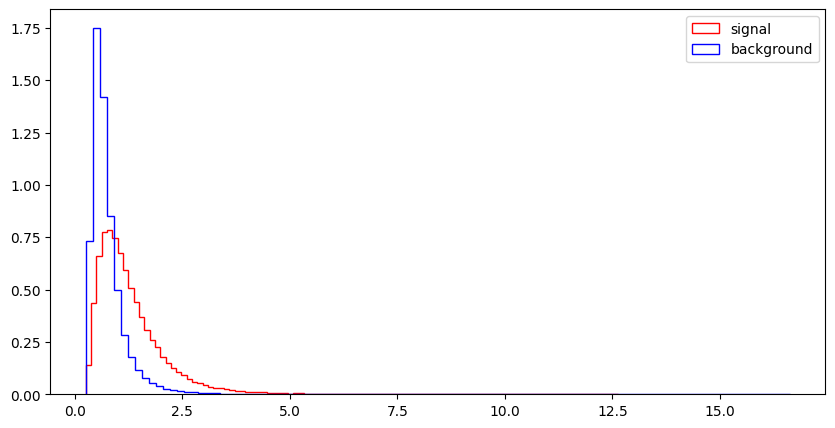

l_1_eta


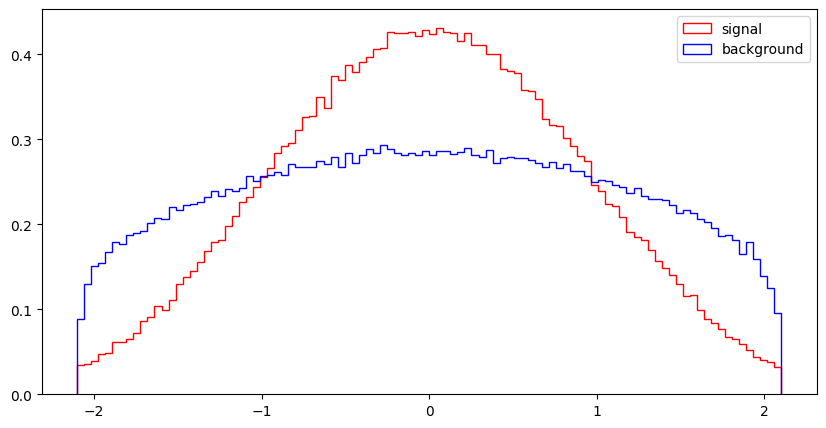

l_1_phi


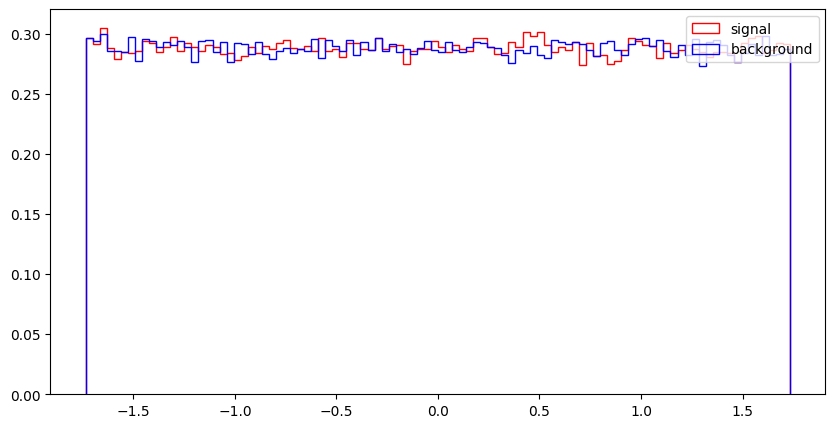

l_2_pT


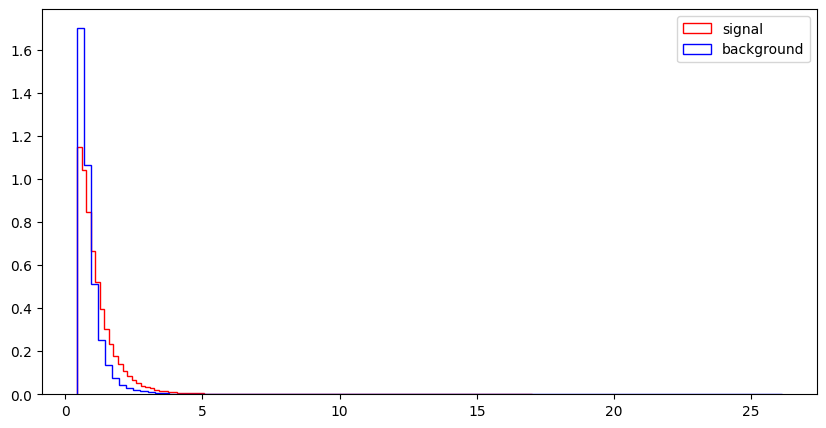

l_2_eta


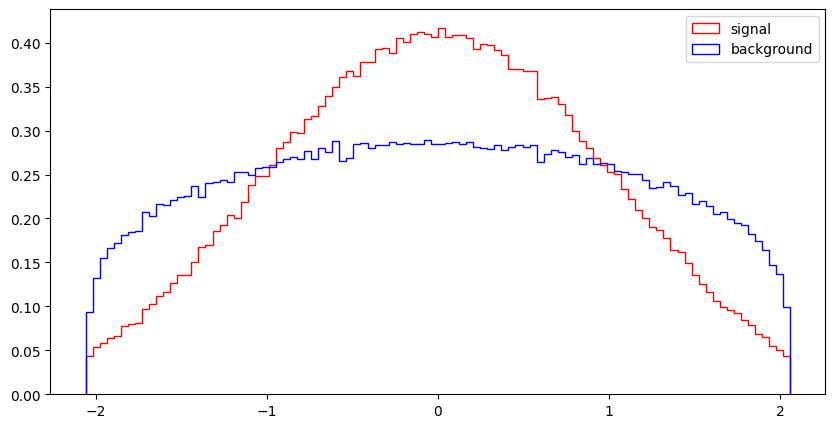

l_2_phi


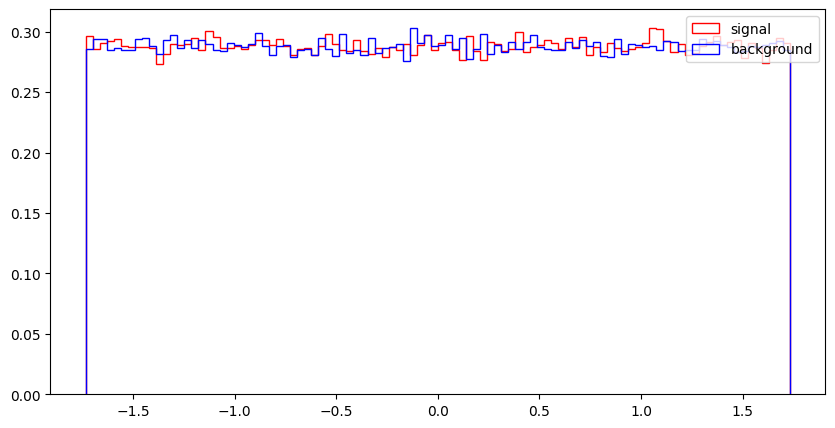

MET


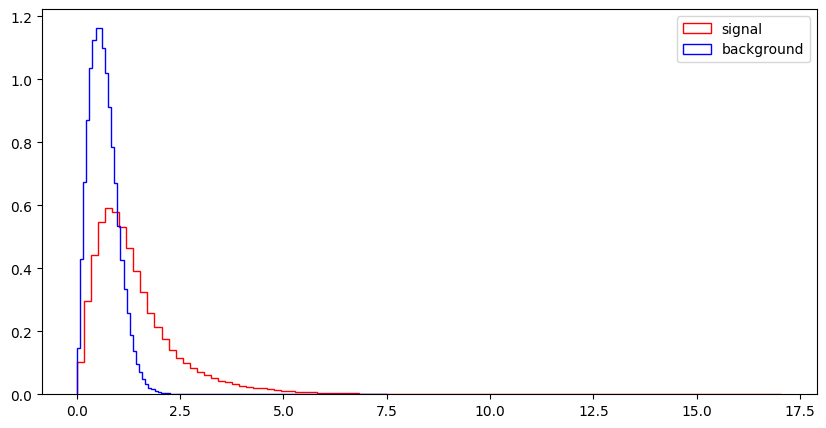

MET_phi


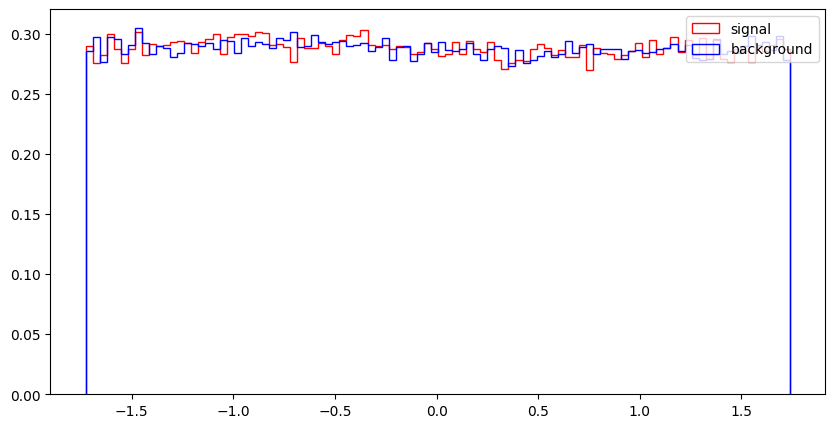

MET_rel


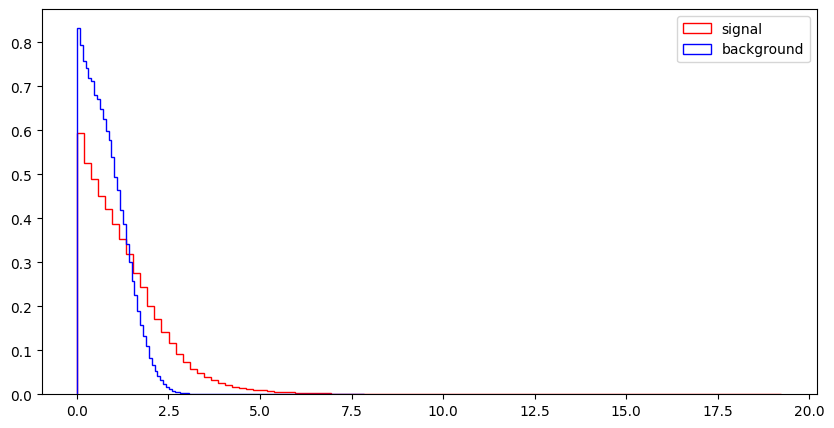

axial_MET


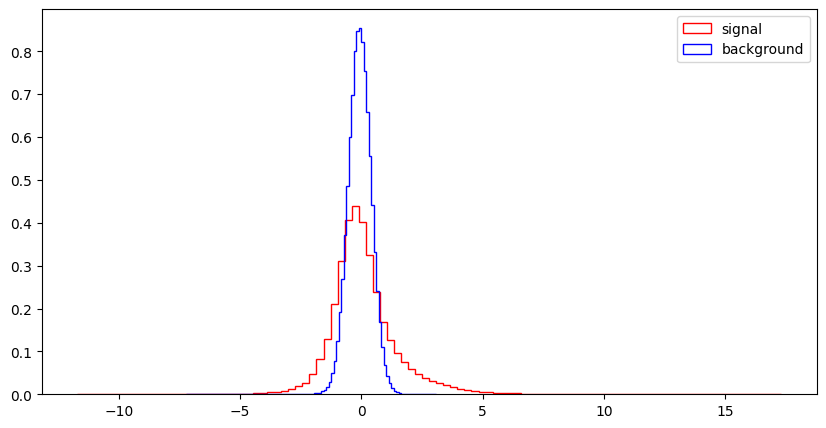

M_R


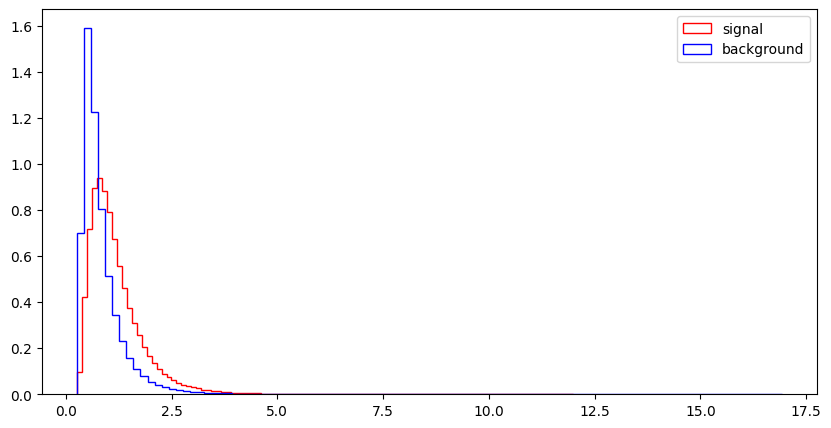

M_TR_2


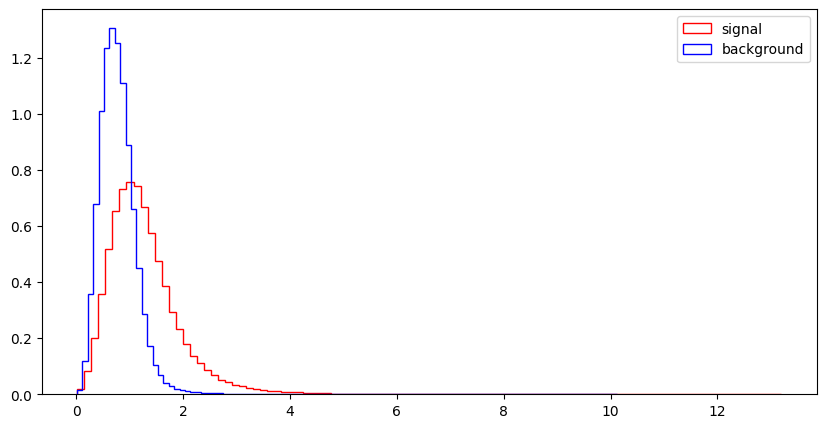

R


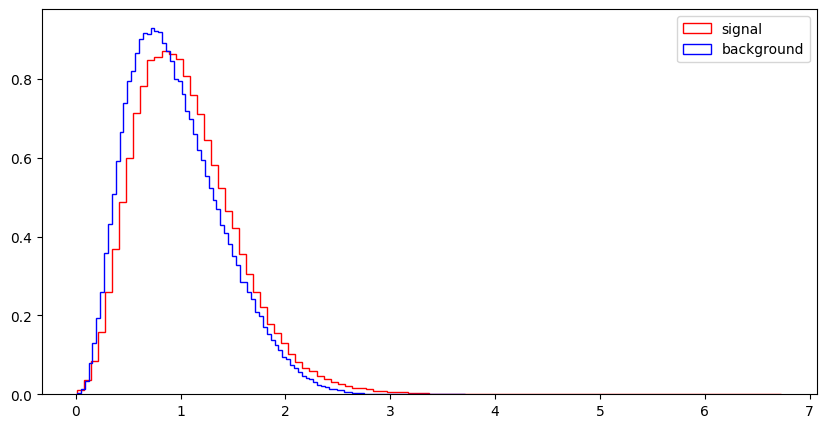

MT2


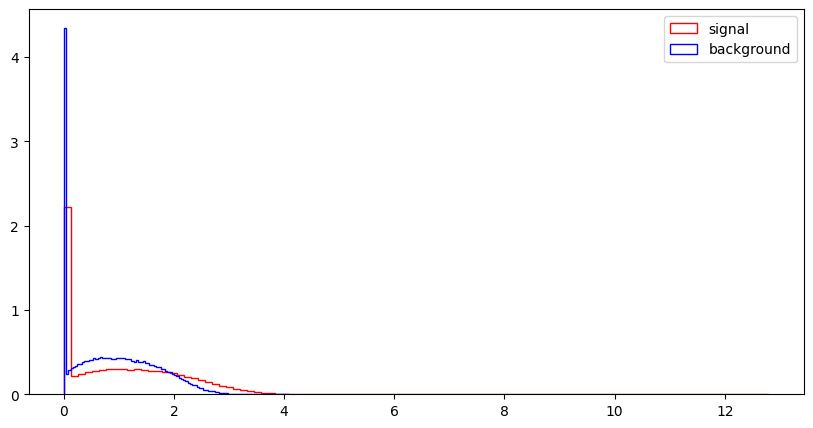

S_R


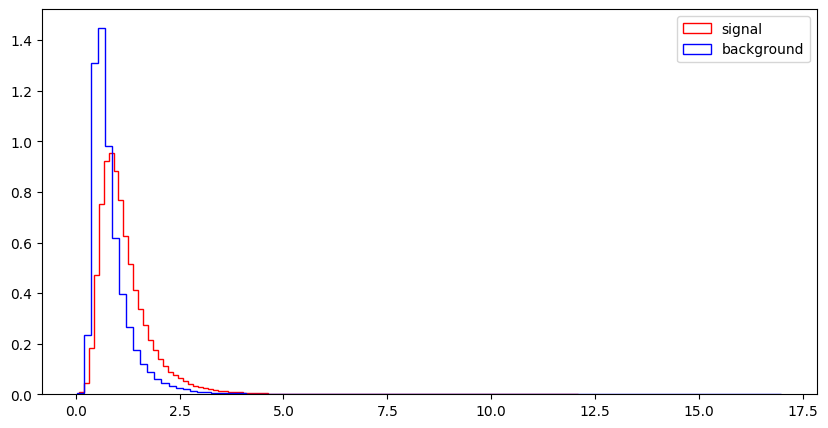

M_Delta_R


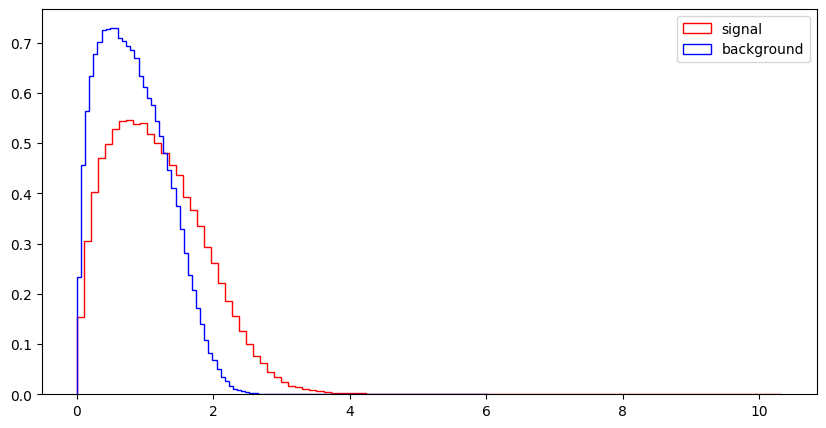

dPhi_r_b


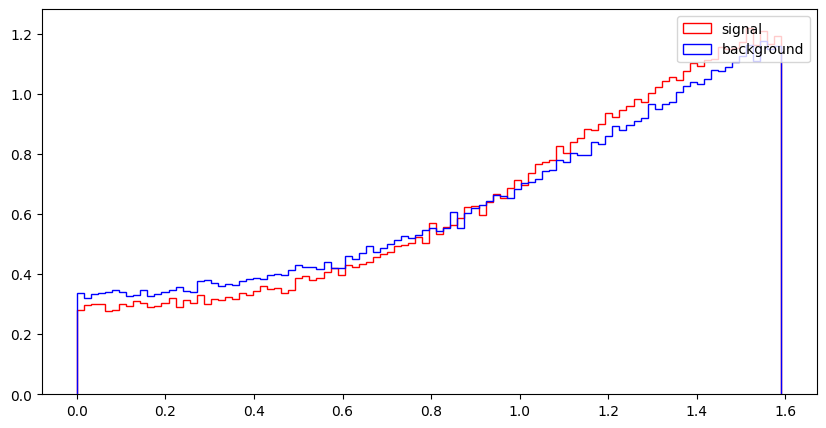

cos_theta_r1


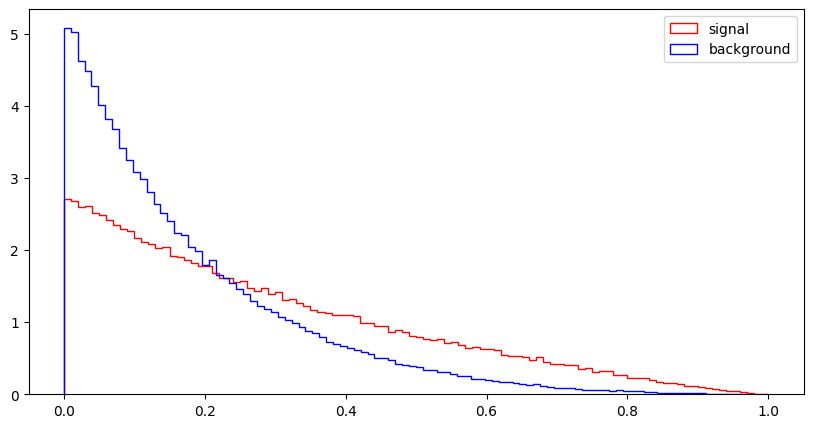

In [18]:
import numpy as np
for var in VarNames[1:]:
    print (var)
    plt.figure(figsize=(10,5))
    plt.hist(np.array(df_sig[var]),bins=100,histtype="step", color="red",label="signal",density=1, stacked=True)
    plt.hist(np.array(df_bkg[var]),bins=100,histtype="step", color="blue", label="background",density=1, stacked=True)
    plt.legend(loc='upper right')
    plt.show()

## Exercise 3: Make nice figures

Now use `matplotlib` to reproduce as closely as you can figures 5 and 6 from the paper. This exercise is intended to get you to familiarize yourself with making nicely formatted `matplotlib` figures with multiple plots. Note that the plots in the paper are actually wrong!

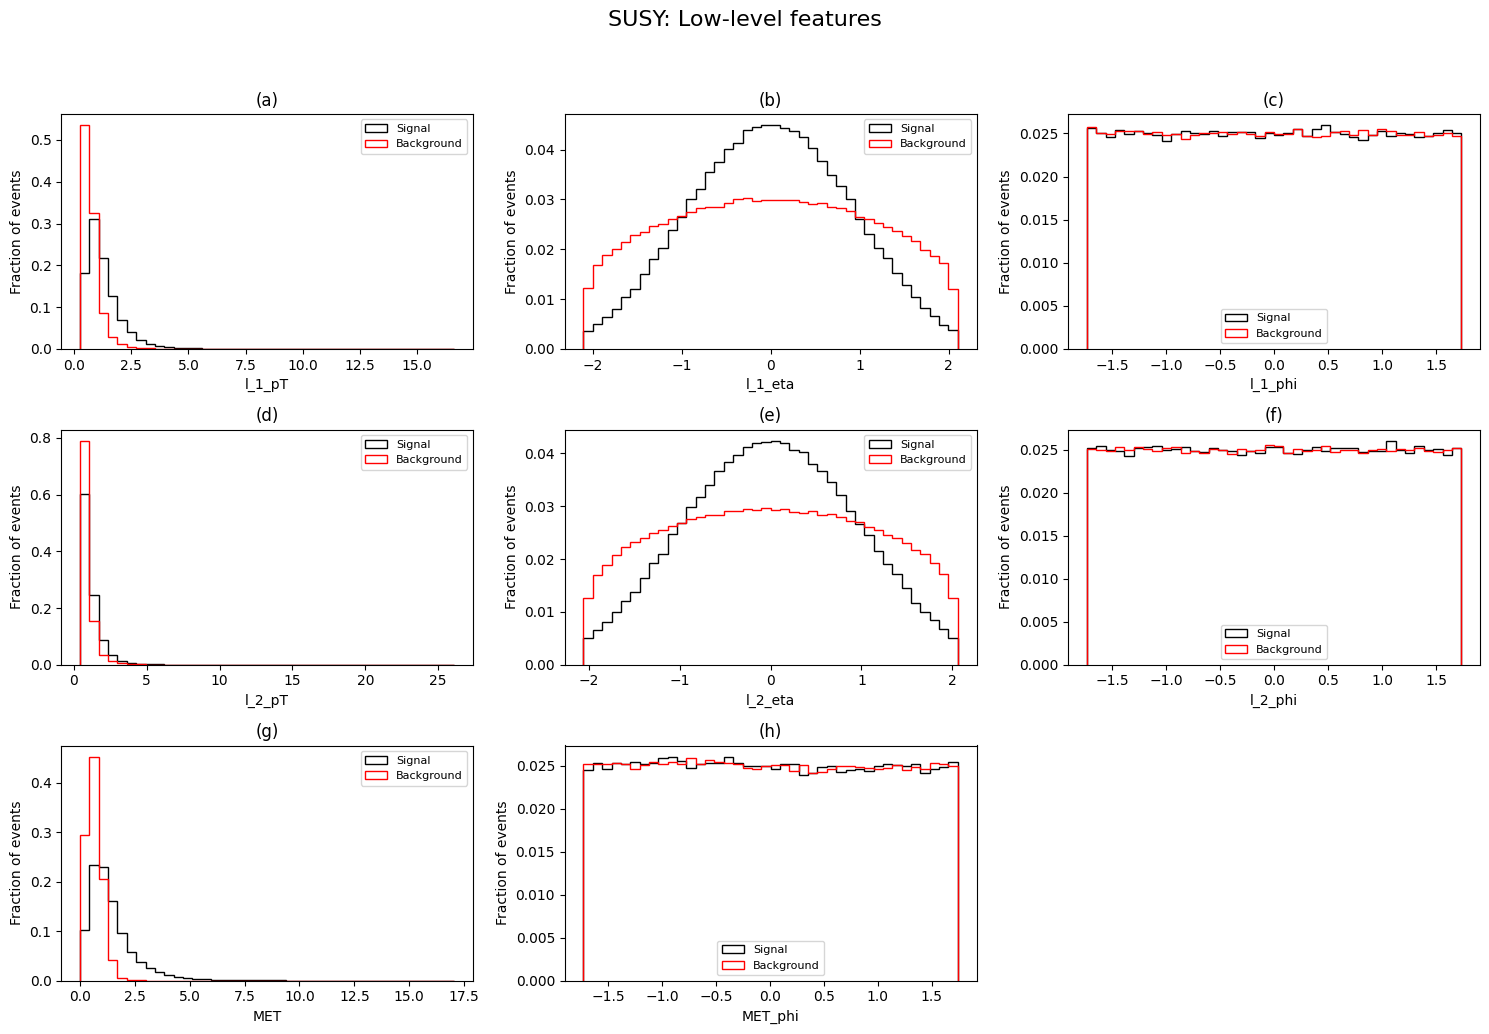

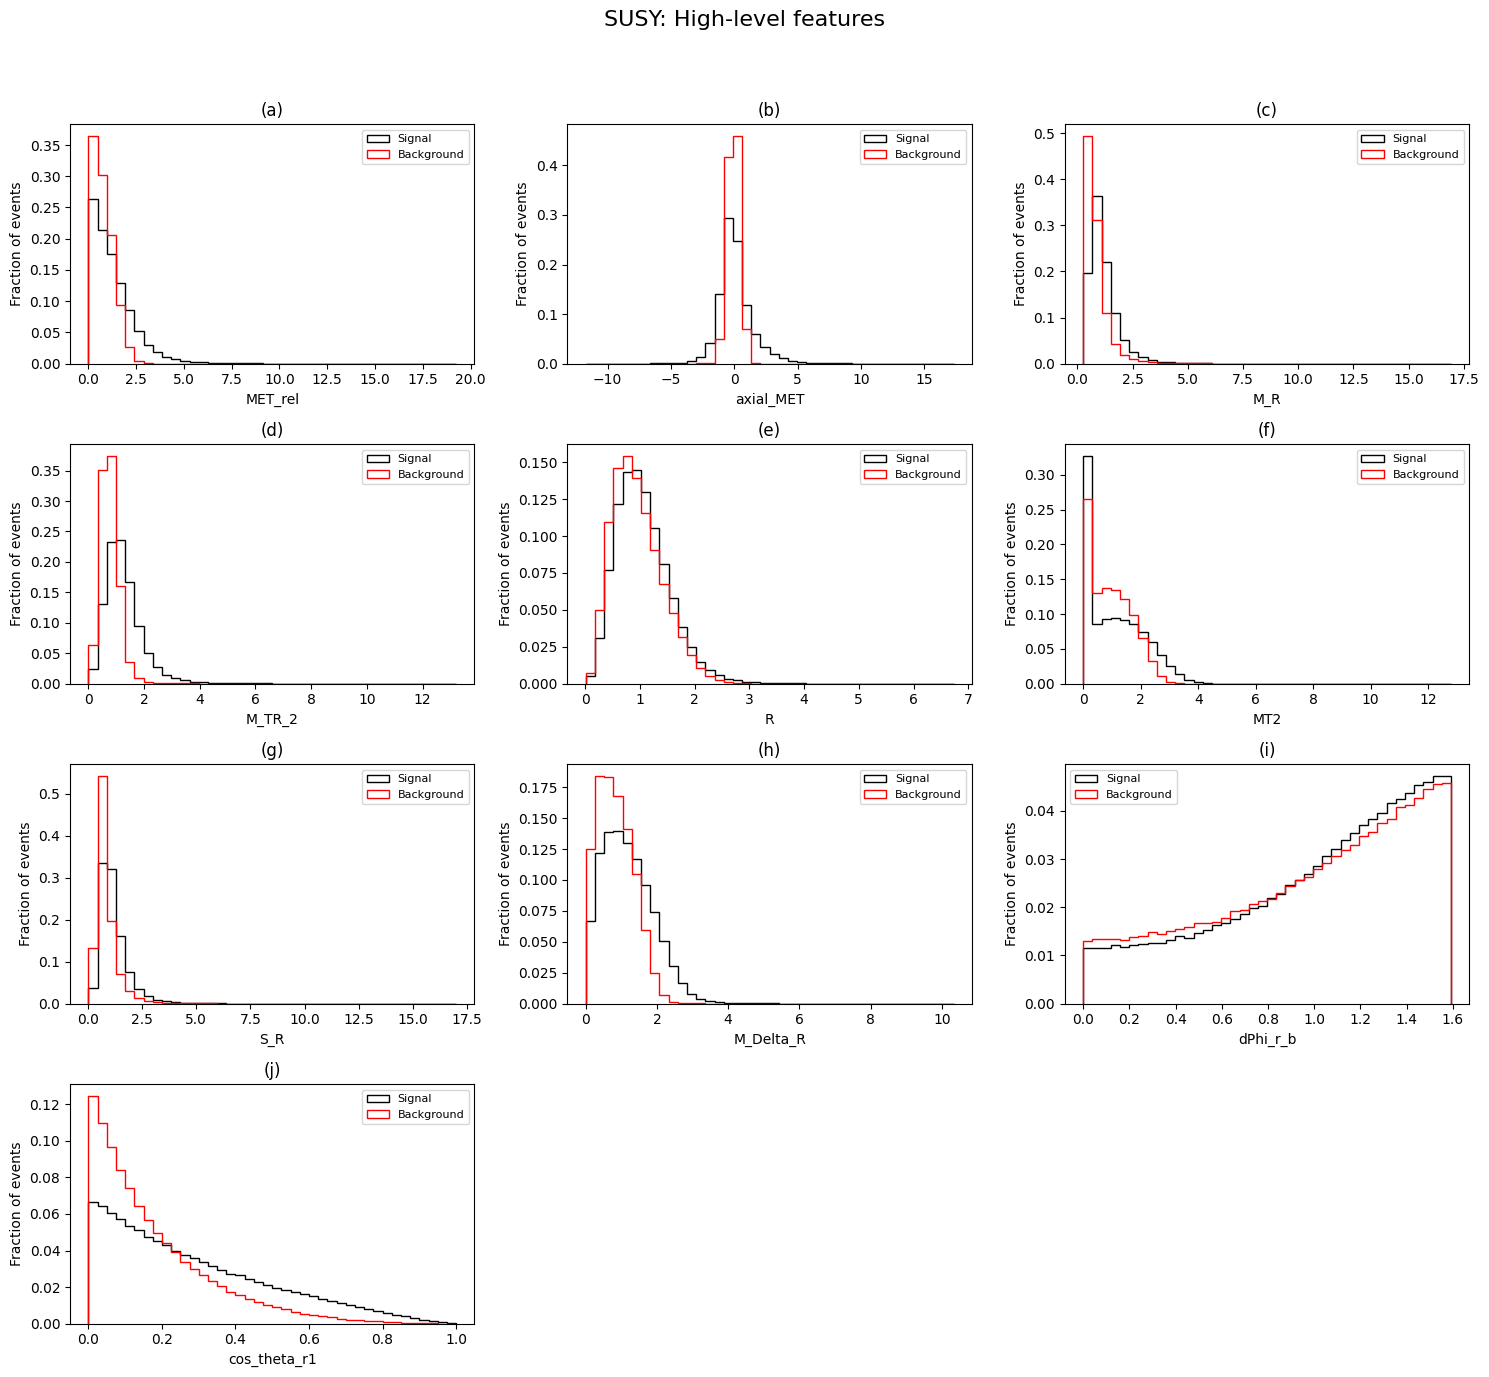

In [19]:
FeatureNames = [name for name in VarNames[1:] if name not in RawNames]

def plot_features(names, title):
    rows = (len(names) + 2) // 3
    fig, axes = plt.subplots(rows, 3, figsize=(15, 3.5 * rows))
    axes = axes.flatten()

    for i, name in enumerate(names):
        ax = axes[i]
        bins = np.histogram_bin_edges(df[name], bins=40)

        for data, color, label in [
            (df_sig, "black", "Signal"),
            (df_bkg, "red", "Background")
        ]:
            values = data[name].to_numpy()
            ax.hist(
                values,
                bins=bins,
                weights=np.ones(len(values)) / len(values),
                histtype="step",
                color=color,
                label=label
            )

        ax.set_xlabel(name)
        ax.set_ylabel("Fraction of events")
        ax.legend(fontsize=8)
        ax.set_title(f"({chr(97 + i)})")

    for ax in axes[len(names):]:
        ax.set_visible(False)

    fig.suptitle(title, fontsize=16)
    plt.tight_layout(rect=[0, 0, 1, 0.95])
    plt.show()

plot_features(RawNames, "SUSY: Low-level features")
plot_features(FeatureNames, "SUSY: High-level features")

## Exercise 4: Correlation

### Exercise 4.1

#### Part a
Write a function that creates pair plots and use it to compare variables in the SUSY sample, separately for low and high-level features. Refer to Lecture 13 for details. Do not use `seaborn`.

#### Part b
Making these plots can be slow because creating each plot initiates a full loop over the data. Make at least one modification to your function in part a to speed it up. Can you propose a different method of creating histograms that would speed up making such pair plots?

#### Part c
Which observables appear to be best for separating signal from background?

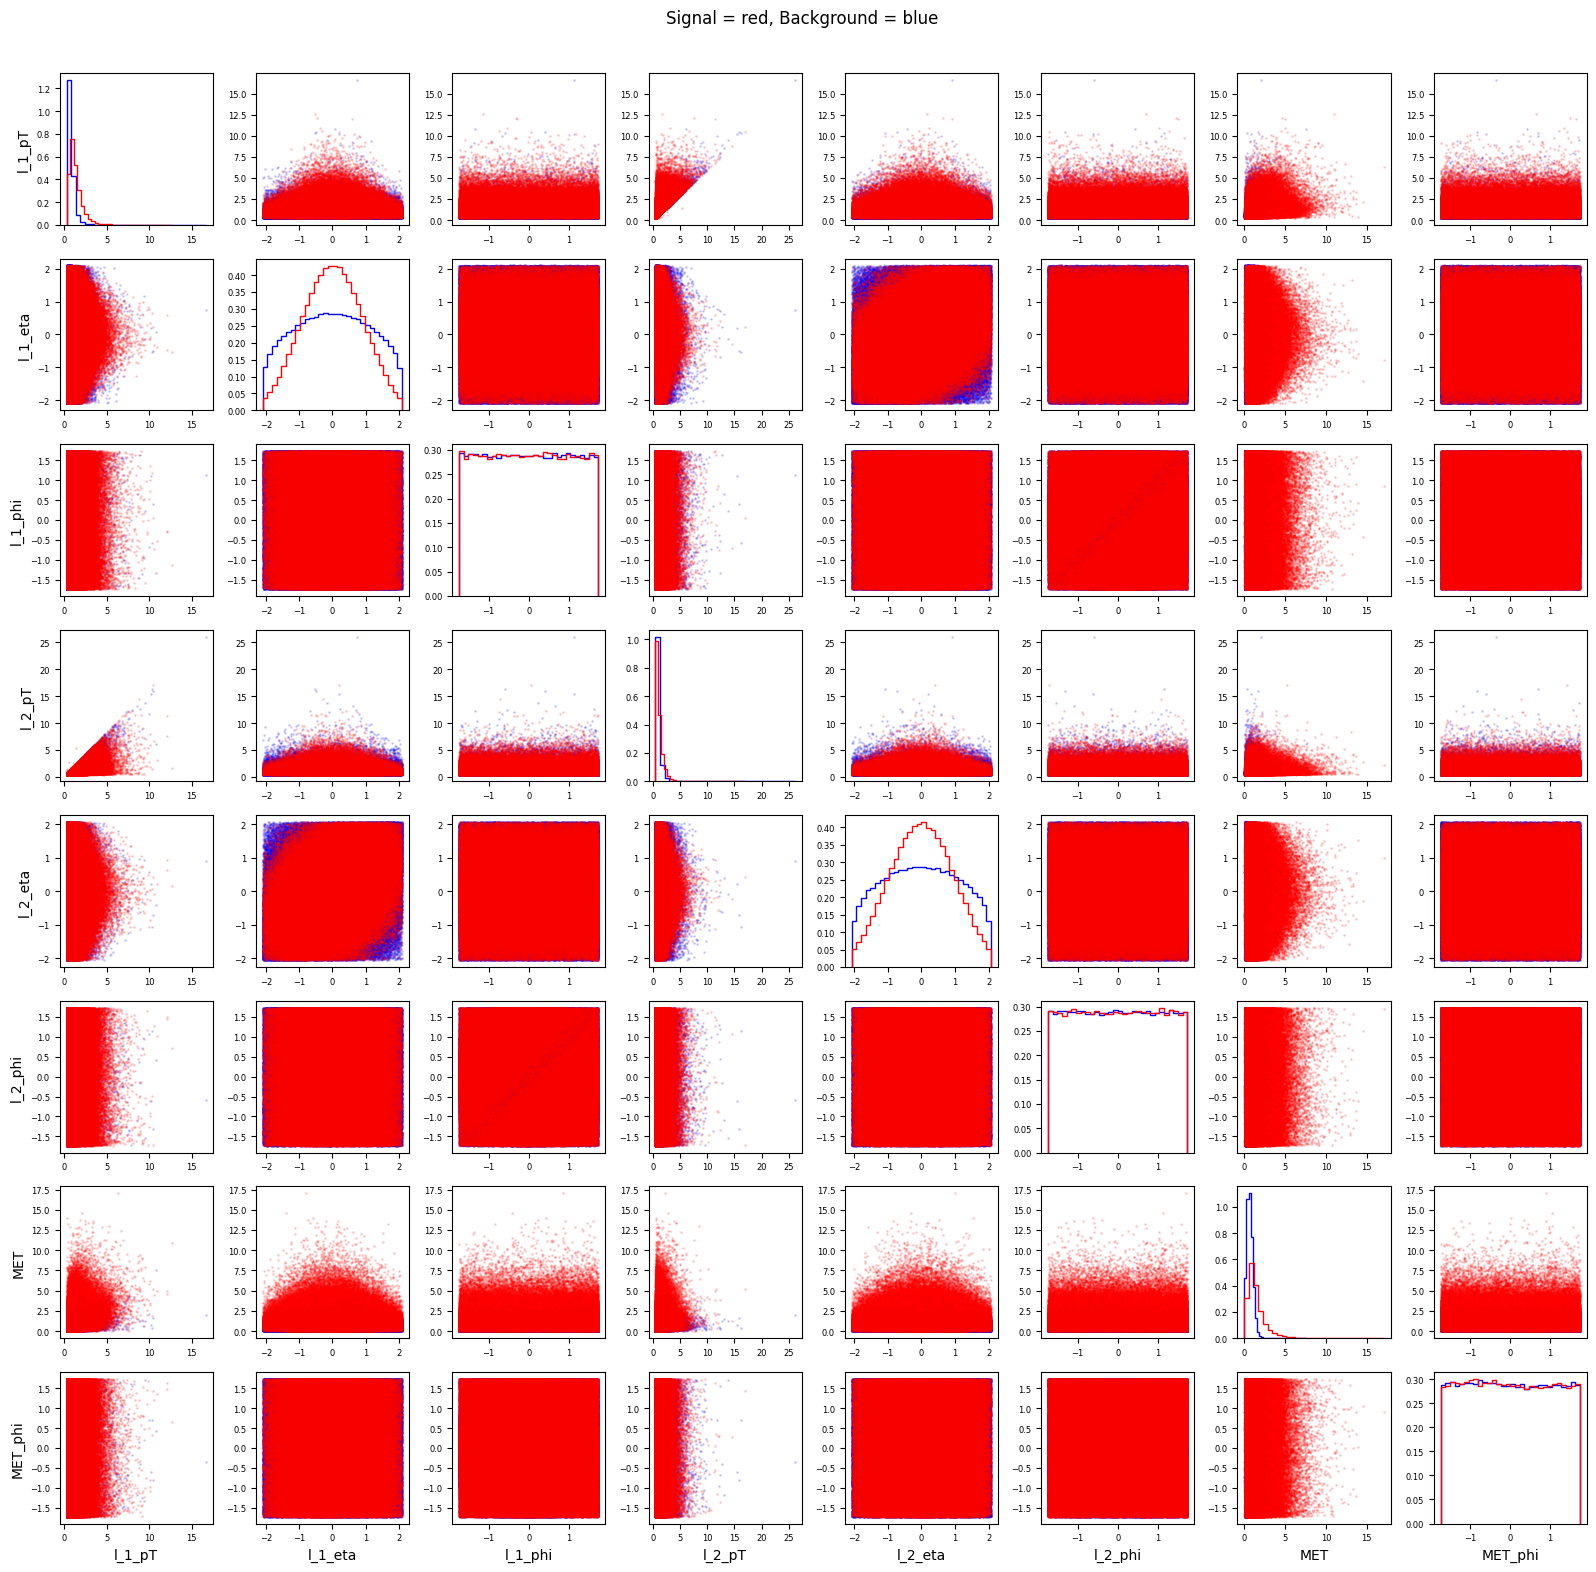

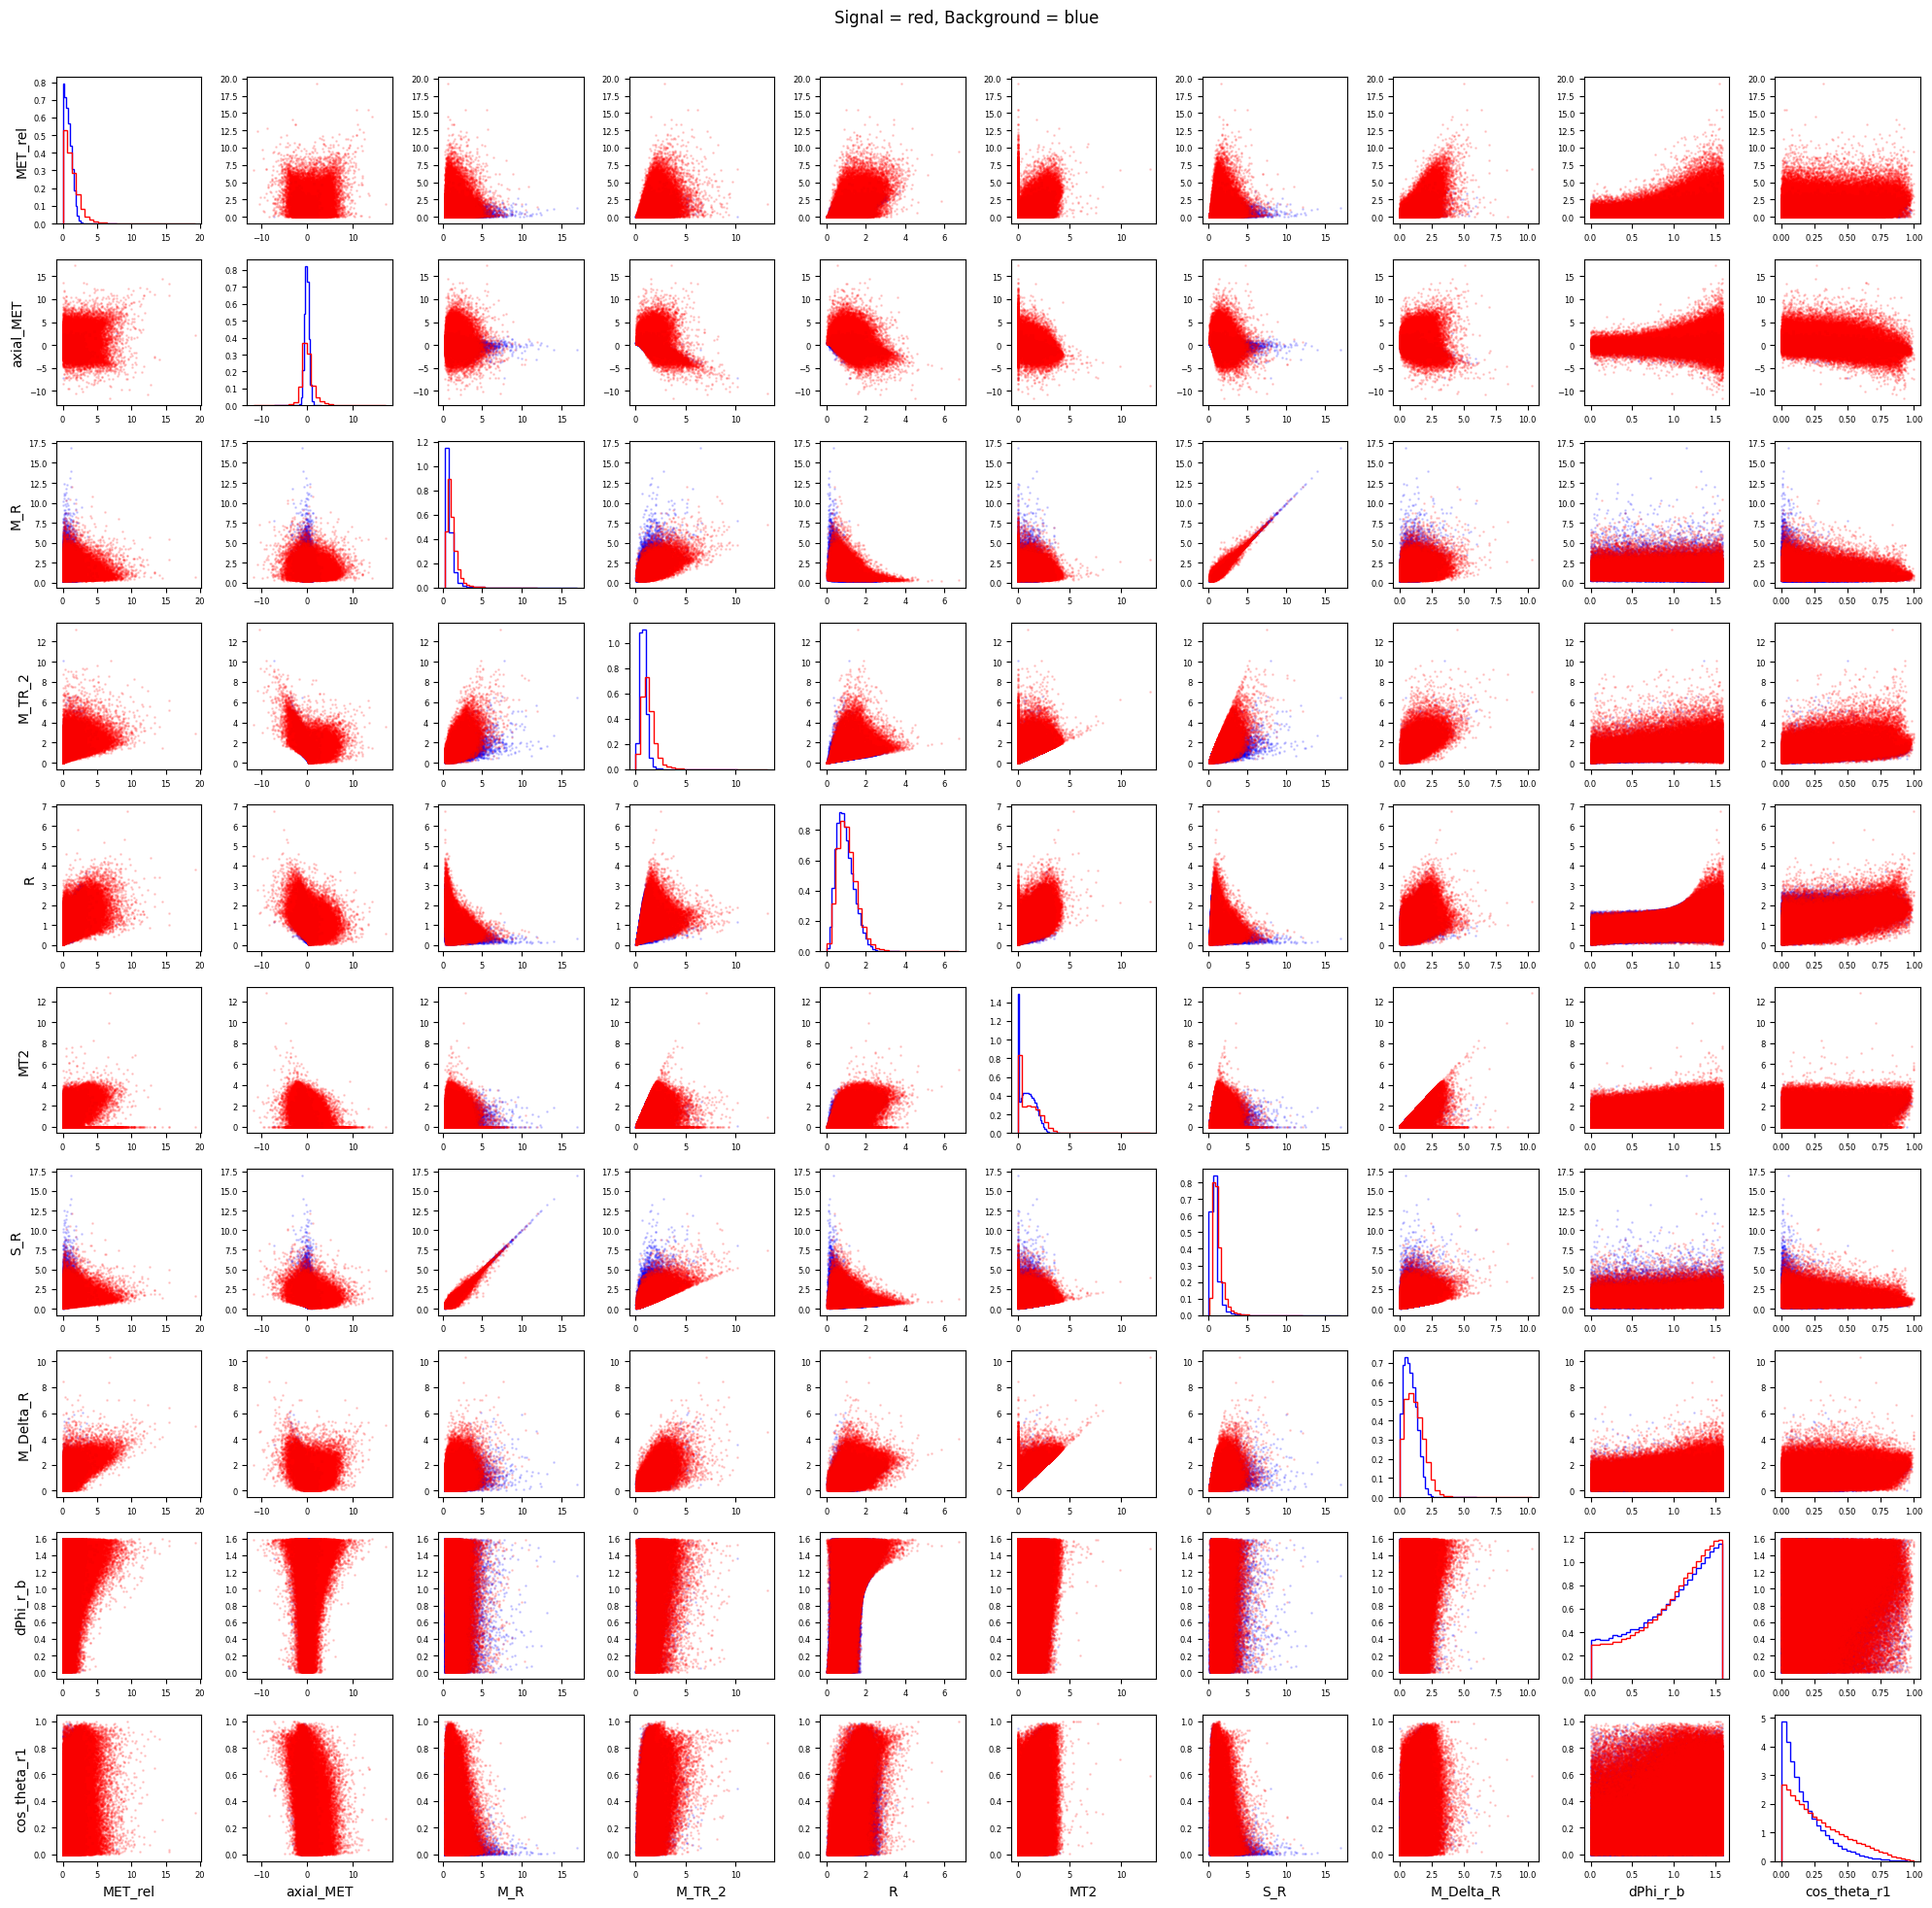

In [20]:
def pair_plots(data, names):
    n = len(names)
    fig, axes = plt.subplots(n, n, figsize=(2 * n, 2 * n))

    for i, y in enumerate(names):
        for j, x in enumerate(names):
            ax = axes[i, j]

            for label, color in [(0, "blue"), (1, "red")]:
                group = data[data["signal"] == label]

                if i == j:
                    ax.hist(group[x], bins=30, density=True,
                            histtype="step", color=color)
                else:
                    ax.scatter(group[x], group[y],
                               s=1, alpha=0.15, color=color,
                               rasterized=True)

            if i == n - 1:
                ax.set_xlabel(x)
            if j == 0:
                ax.set_ylabel(y)

            ax.tick_params(labelsize=6)

    fig.suptitle("Signal = red, Background = blue")
    plt.tight_layout(rect=[0, 0, 1, 0.97])
    plt.show()

pair_plots(df, RawNames)
pair_plots(df, FeatureNames)

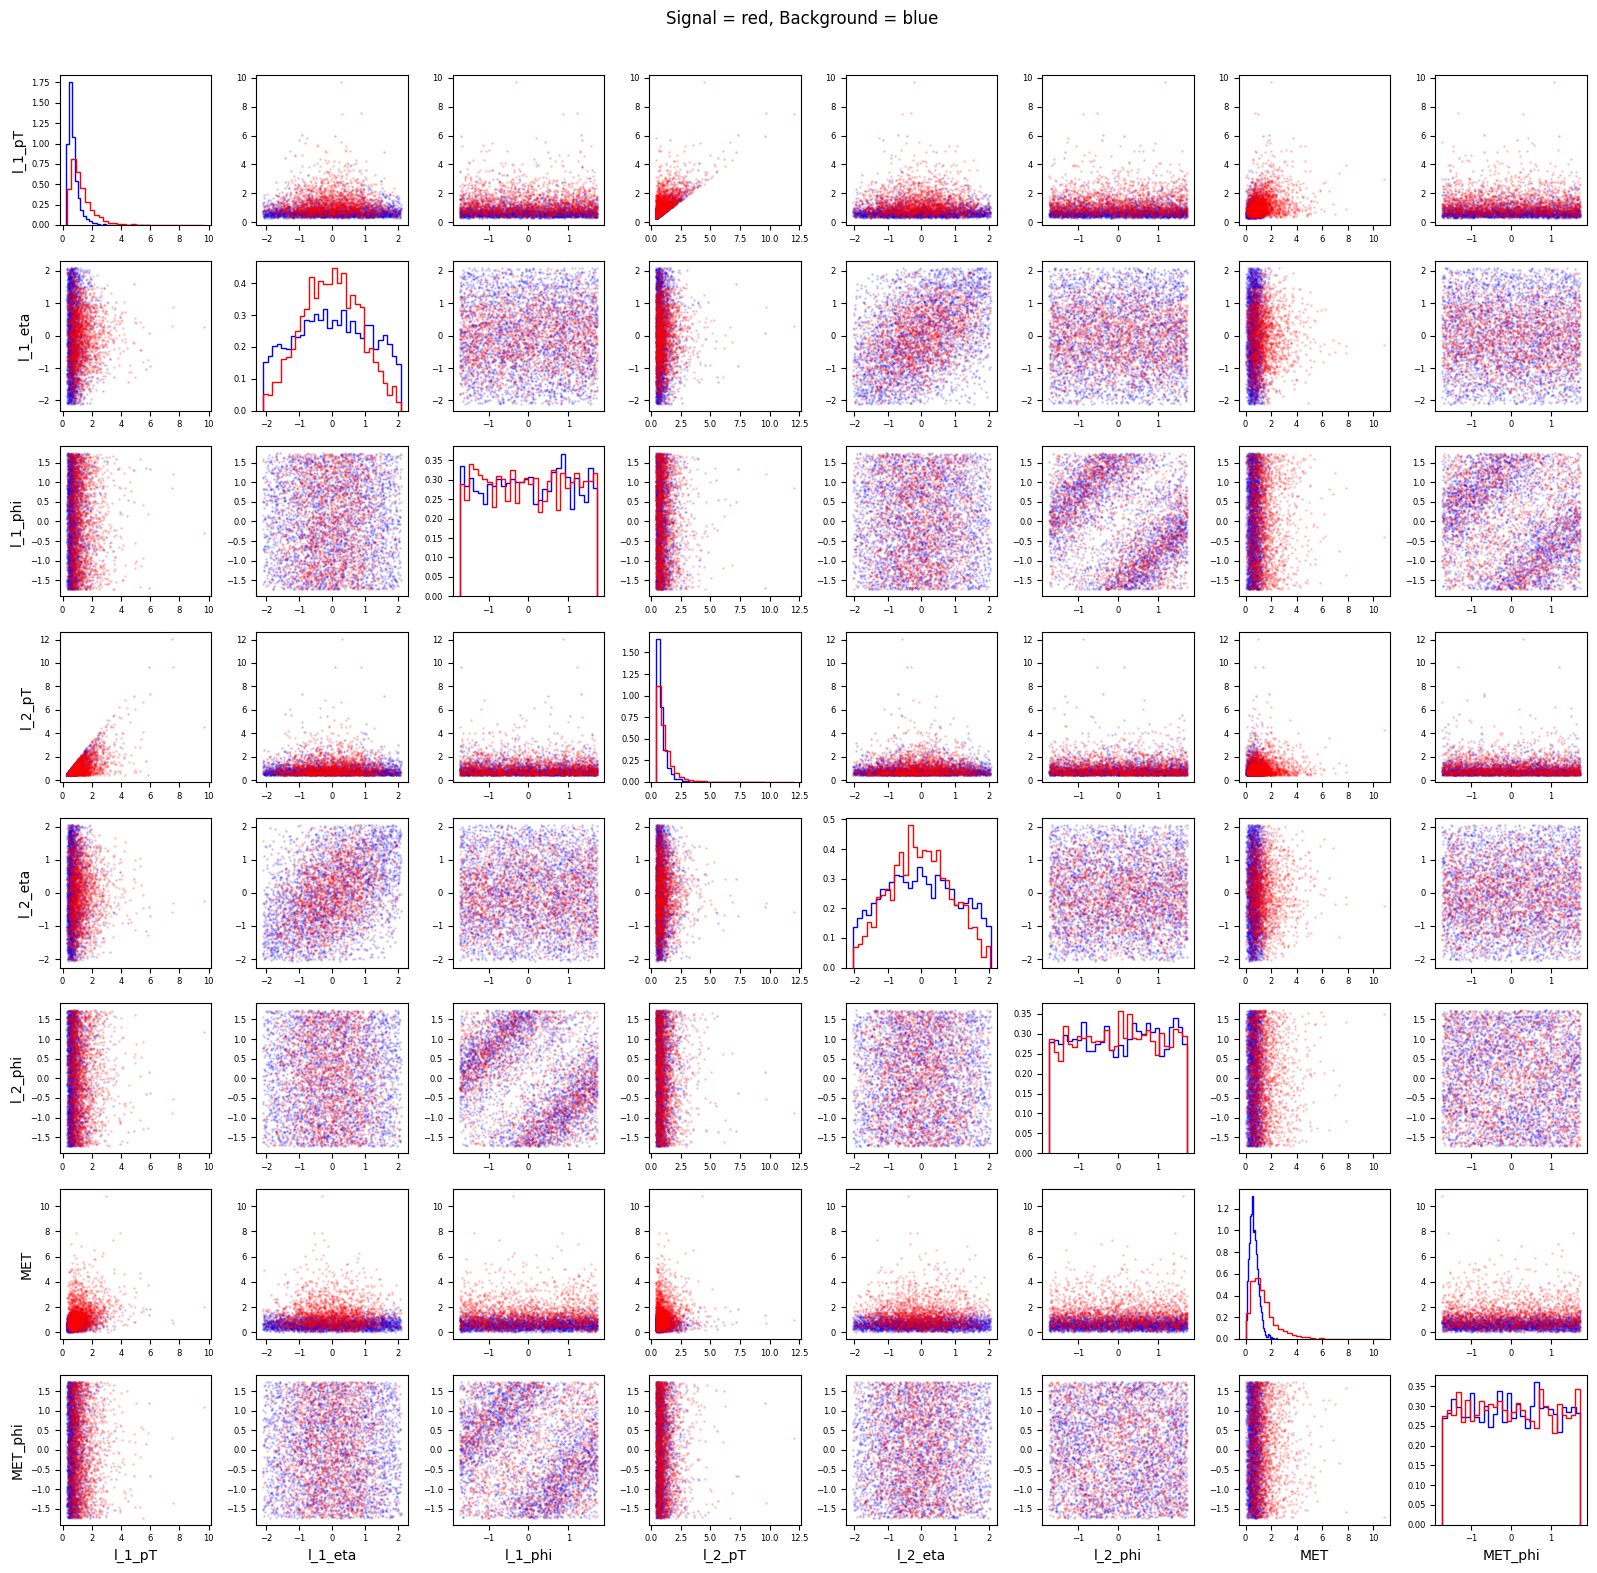

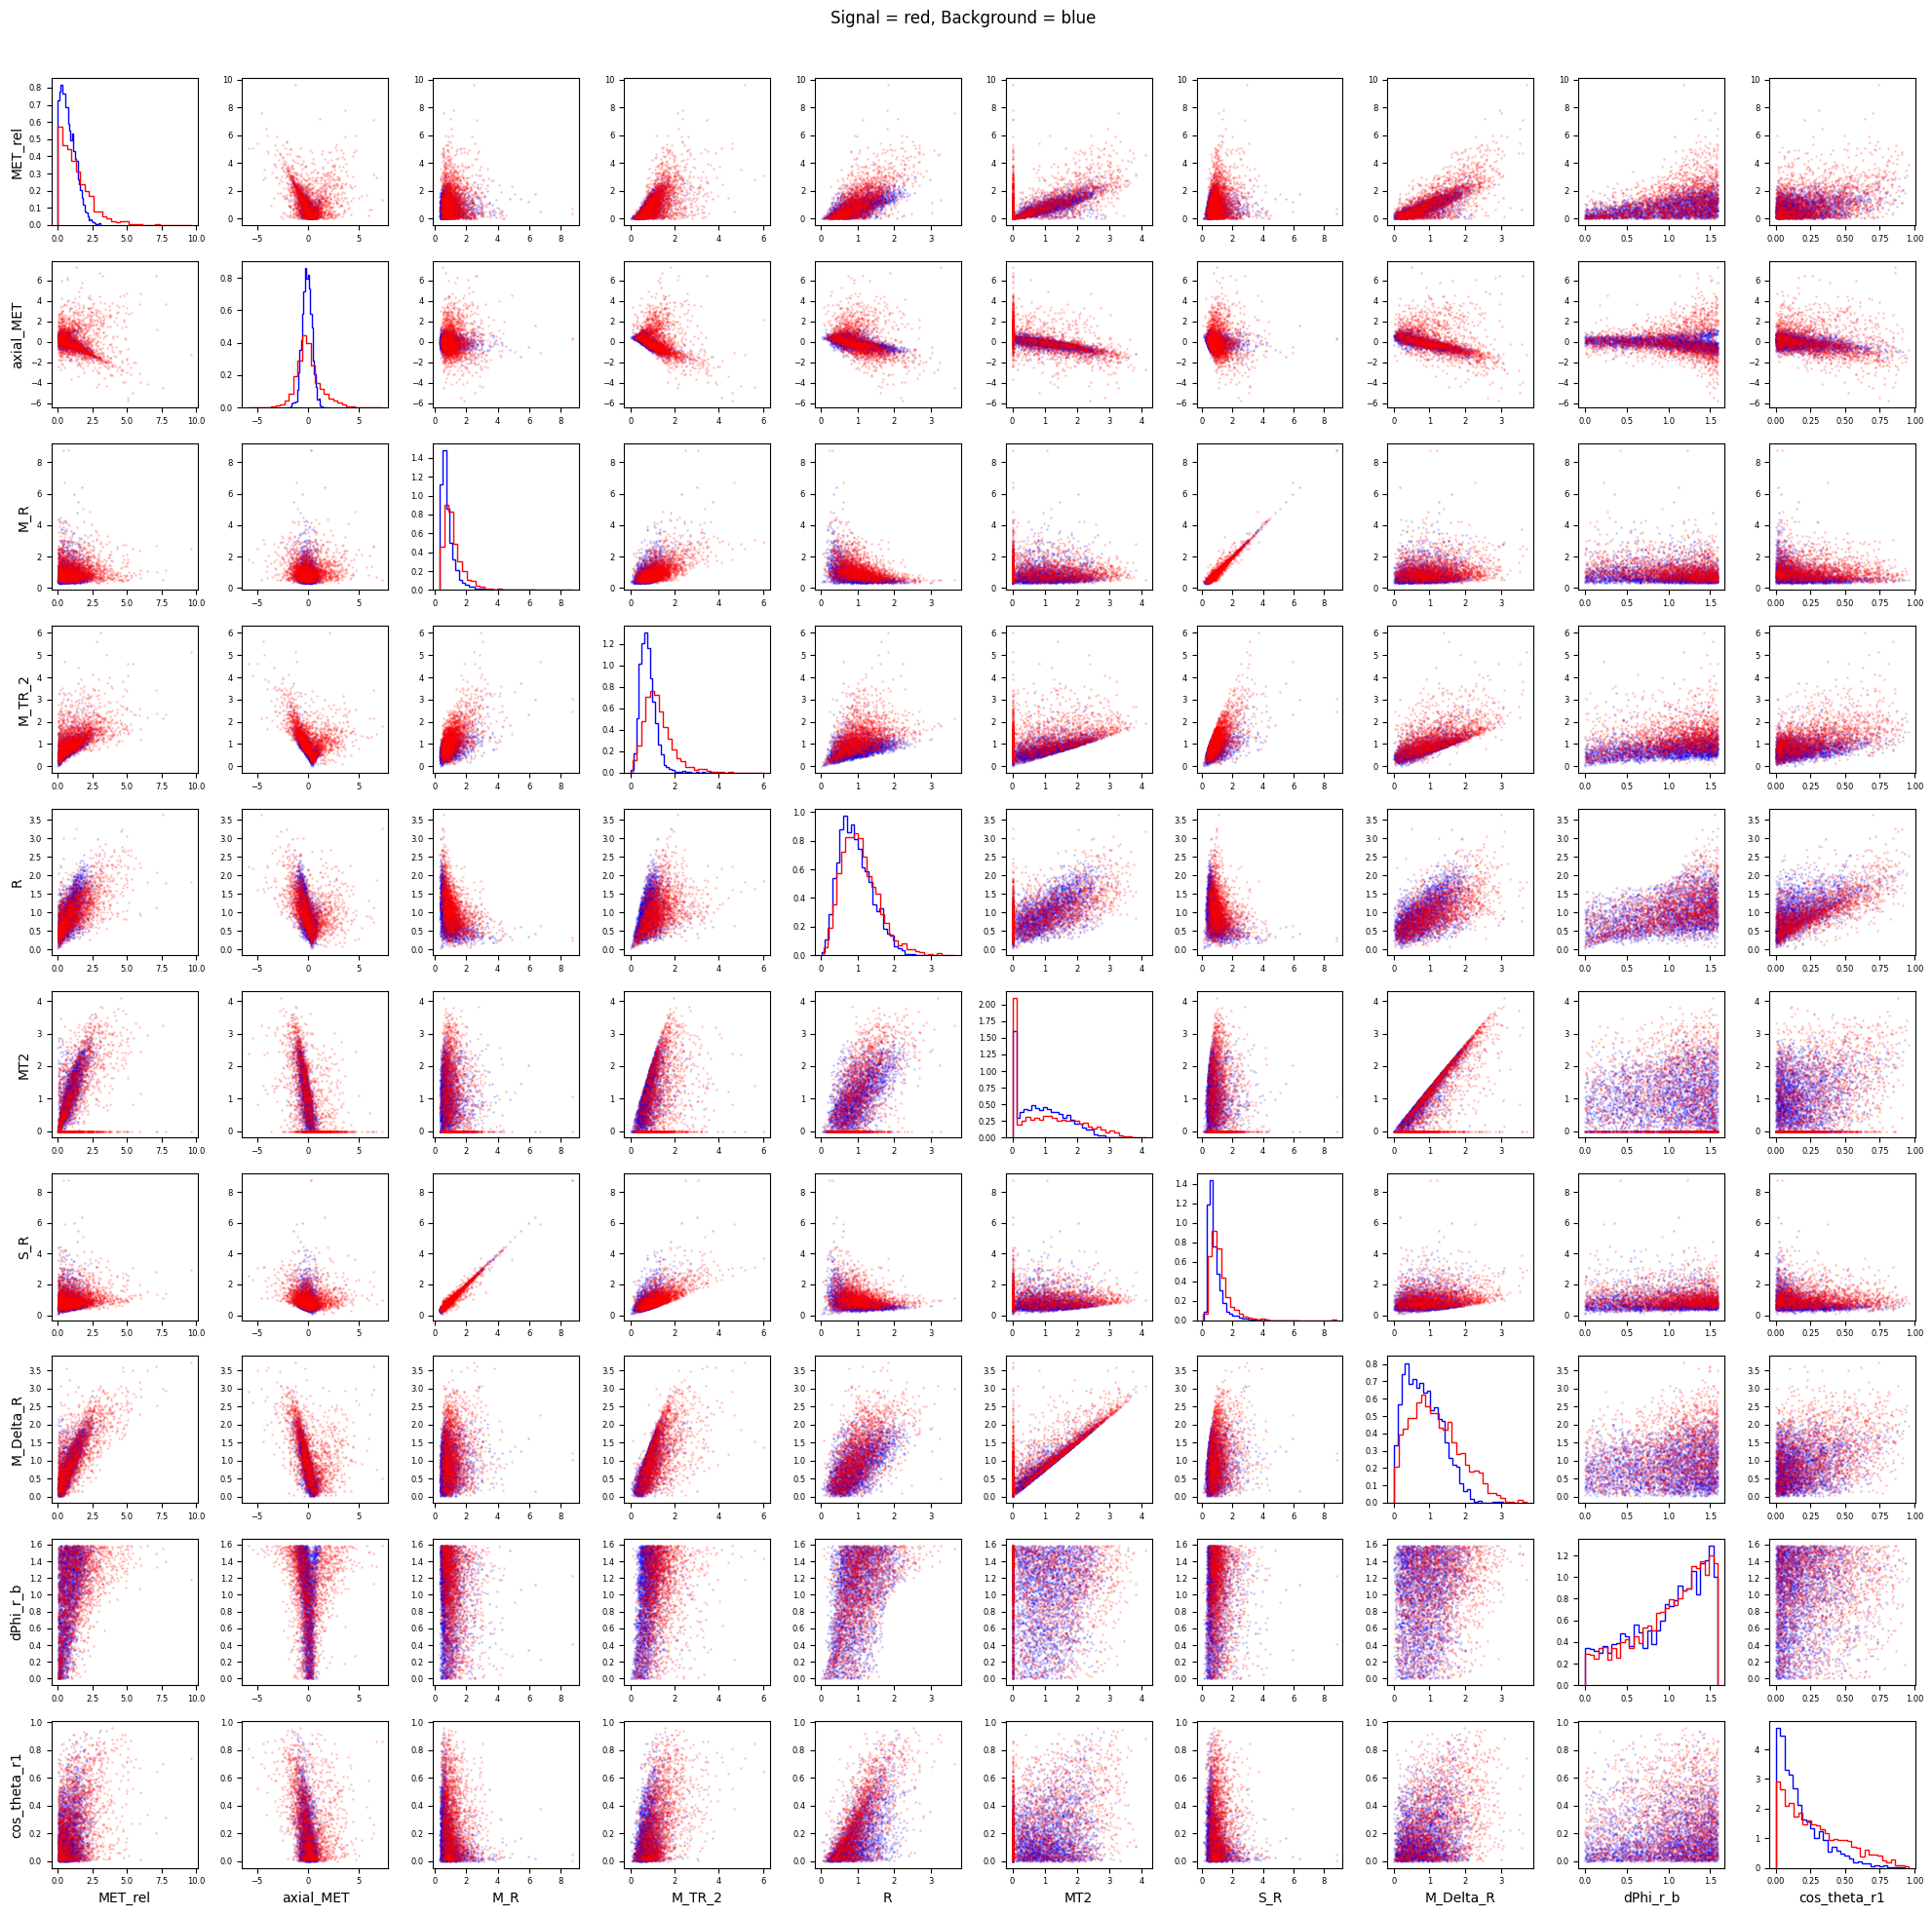

In [21]:
small_df = df.sample(n=5000, random_state=42)

pair_plots(small_df, RawNames)
pair_plots(small_df, FeatureNames)

I sped up the plots by using a random sample of 5,000 rows instead of all 500,000 rows. This reduces the amount of data plotted while still showing the main patterns. Another approach would be to use NumPy’s histogram2d to count points in bins and display those counts with imshow instead of drawing every point.

In [22]:
from sklearn.metrics import roc_auc_score

scores = {}

for name in VarNames[1:]:
    auc = roc_auc_score(df["signal"], df[name])
    scores[name] = max(auc, 1 - auc)

ranking = pd.Series(scores).sort_values(ascending=False)
print(ranking.head(6))

MET             0.770968
l_1_pT          0.763591
M_TR_2          0.758178
M_R             0.704659
S_R             0.699456
cos_theta_r1    0.644834
dtype: float64


MET, l_1_pT, and M_TR_2 appear to be the best variables for separating signal from background. Their AUC scores were about 0.771, 0.764, and 0.758. MET had the highest score, making it the best of these individual variables.

### Exercise 4.2

#### Part a
Install [tabulate](https://github.com/astanin/python-tabulate).

#### Part b
Use numpy to compute the [covariance matrix](https://numpy.org/doc/stable/reference/generated/numpy.cov.html) and [correlation matrix](https://numpy.org/doc/stable/reference/generated/numpy.corrcoef.html) between all observables, and separately between low and high-level features.

#### Part c
Use tabulate to create a well formatted table of the covariance and correlation matrices, with nice headings and appropriate significant figures. Embed the table into this notebook.

#### Part d
Write a function that takes a dataset and appropriate arguments and performs steps b and c.  

Hint: Example code for embedding a `tabulate` table into a notebook:

In [23]:
%pip install tabulate

In [24]:
from tabulate import tabulate
from IPython.display import HTML, display

def matrix_tables(data, names, title):
    values = data[names].to_numpy()

    covariance = np.cov(values, rowvar=False)
    correlation = np.corrcoef(values, rowvar=False)

    for matrix, label in [
        (covariance, "Covariance"),
        (correlation, "Correlation")
    ]:
        print(title + " - " + label)

        table = pd.DataFrame(matrix, index=names, columns=names)

        display(HTML(tabulate(
            table,
            headers="keys",
            tablefmt="html",
            showindex=True,
            floatfmt=".3g"
        )))

matrix_tables(df, VarNames[1:], "All observables")
matrix_tables(df, RawNames, "Low-level features")
matrix_tables(df, FeatureNames, "High-level features")

All observables - Covariance


,l_1_pT,l_1_eta,l_1_phi,l_2_pT,l_2_eta,l_2_phi,MET,MET_phi,MET_rel,axial_MET,M_R,M_TR_2,R,MT2,S_R,M_Delta_R,dPhi_r_b,cos_theta_r1
l_1_pT,0.467,-0.000397,7.66e-05,0.305,-0.000349,0.000737,0.228,-0.000937,0.0975,-0.00973,0.364,0.287,-0.0597,-0.0124,0.343,0.0977,-0.0469,0.0222
l_1_eta,-0.000397,1,-0.000858,-0.000163,0.408,-0.00104,-0.00215,-0.000589,-0.00137,-0.00111,-0.000554,-0.000669,0.000301,0.000427,-0.000604,-0.000987,-0.00074,0.000322
l_1_phi,7.66e-05,-0.000858,1,0.00131,0.000251,-0.267,0.000766,-0.185,0.000706,-0.00187,0.00106,0.000869,0.000202,0.00106,0.00146,0.000901,0.000994,0.000259
l_2_pT,0.305,-0.000163,0.00131,0.425,-0.000576,0.000156,0.0795,-0.00156,-0.000534,0.0513,0.325,0.163,-0.0994,-0.0689,0.322,0.00572,-0.00383,-0.0279
l_2_eta,-0.000349,0.408,0.000251,-0.000576,1.01,0.000442,0.000382,-0.000322,0.00108,-0.000756,-0.000608,1.89e-05,0.000321,0.0014,-0.000679,0.00067,-0.000307,0.000296
l_2_phi,0.000737,-0.00104,-0.267,0.000156,0.000442,1,-0.000304,-0.0354,0.00145,-0.0018,0.00076,0.000509,0.000551,0.00226,0.000906,0.00133,-0.000241,3.7e-05
MET,0.228,-0.00215,0.000766,0.0795,0.000382,-0.000304,0.762,-0.00279,0.546,0.154,0.145,0.365,0.188,0.155,0.166,0.315,0.146,0.0731
MET_phi,-0.000937,-0.000589,-0.185,-0.00156,-0.000322,-0.0354,-0.00279,1,-0.0049,-0.000442,-0.00148,-0.0012,-0.00023,8.39e-05,-0.00171,-0.00057,-0.00171,0.000119
MET_rel,0.0975,-0.00137,0.000706,-0.000534,0.00108,0.00145,0.546,-0.0049,0.79,-0.12,0.0437,0.302,0.249,0.409,0.0823,0.415,0.146,0.0553
axial_MET,-0.00973,-0.00111,-0.00187,0.0513,-0.000756,-0.0018,0.154,-0.000442,-0.12,1.01,0.0171,-0.185,-0.181,-0.461,-0.0414,-0.233,-0.0251,-0.0537


All observables - Correlation


,l_1_pT,l_1_eta,l_1_phi,l_2_pT,l_2_eta,l_2_phi,MET,MET_phi,MET_rel,axial_MET,M_R,M_TR_2,R,MT2,S_R,M_Delta_R,dPhi_r_b,cos_theta_r1
l_1_pT,1,-0.000579,0.000112,0.684,-0.000509,0.00108,0.383,-0.00137,0.16,-0.0142,0.851,0.723,-0.186,-0.0211,0.811,0.229,-0.157,0.165
l_1_eta,-0.000579,1,-0.000854,-0.000249,0.406,-0.00104,-0.00245,-0.000587,-0.00154,-0.0011,-0.000882,-0.00115,0.000639,0.000496,-0.000975,-0.00158,-0.00169,0.00163
l_1_phi,0.000112,-0.000854,1,0.00201,0.000249,-0.266,0.000876,-0.184,0.000793,-0.00186,0.00169,0.00149,0.000427,0.00123,0.00236,0.00144,0.00228,0.00131
l_2_pT,0.684,-0.000249,0.00201,1,-0.00088,0.000239,0.14,-0.00239,-0.000921,0.0785,0.797,0.43,-0.324,-0.123,0.799,0.0141,-0.0135,-0.217
l_2_eta,-0.000509,0.406,0.000249,-0.00088,1,0.000439,0.000436,-0.000321,0.00122,-0.000752,-0.000967,3.24e-05,0.000679,0.00162,-0.00109,0.00107,-0.000701,0.0015
l_2_phi,0.00108,-0.00104,-0.266,0.000239,0.000439,1,-0.000348,-0.0353,0.00162,-0.00179,0.00121,0.000874,0.00117,0.00263,0.00146,0.00212,-0.000552,0.000188
MET,0.383,-0.00245,0.000876,0.14,0.000436,-0.000348,1,-0.00319,0.704,0.176,0.264,0.72,0.457,0.206,0.307,0.579,0.383,0.425
MET_phi,-0.00137,-0.000587,-0.184,-0.00239,-0.000321,-0.0353,-0.00319,1,-0.0055,-0.00044,-0.00236,-0.00206,-0.000487,9.75e-05,-0.00276,-0.000913,-0.00391,0.000605
MET_rel,0.16,-0.00154,0.000793,-0.000921,0.00122,0.00162,0.704,-0.0055,1,-0.134,0.0785,0.584,0.595,0.535,0.15,0.748,0.378,0.316
axial_MET,-0.0142,-0.0011,-0.00186,0.0785,-0.000752,-0.00179,0.176,-0.00044,-0.134,1,0.0273,-0.317,-0.383,-0.535,-0.0668,-0.373,-0.0574,-0.272


Low-level features - Covariance


...

,l_1_pT,l_1_eta,l_1_phi,l_2_pT,l_2_eta,l_2_phi,MET,MET_phi
l_1_pT,1,-0.000579,0.000112,0.684,-0.000509,0.00108,0.383,-0.00137
l_1_eta,-0.000579,1,-0.000854,-0.000249,0.406,-0.00104,-0.00245,-0.000587
l_1_phi,0.000112,-0.000854,1,0.00201,0.000249,-0.266,0.000876,-0.184
l_2_pT,0.684,-0.000249,0.00201,1,-0.00088,0.000239,0.14,-0.00239
l_2_eta,-0.000509,0.406,0.000249,-0.00088,1,0.000439,0.000436,-0.000321
l_2_phi,0.00108,-0.00104,-0.266,0.000239,0.000439,1,-0.000348,-0.0353
MET,0.383,-0.00245,0.000876,0.14,0.000436,-0.000348,1,-0.00319
MET_phi,-0.00137,-0.000587,-0.184,-0.00239,-0.000321,-0.0353,-0.00319,1


High-level features - Covariance


,MET_rel,axial_MET,M_R,M_TR_2,R,MT2,S_R,M_Delta_R,dPhi_r_b,cos_theta_r1
MET_rel,0.79,-0.12,0.0437,0.302,0.249,0.409,0.0823,0.415,0.146,0.0553
axial_MET,-0.12,1.01,0.0171,-0.185,-0.181,-0.461,-0.0414,-0.233,-0.0251,-0.0537
M_R,0.0437,0.0171,0.392,0.21,-0.113,-0.0365,0.38,0.0739,-0.029,-0.0143
M_TR_2,0.302,-0.185,0.21,0.338,0.104,0.189,0.228,0.242,0.0581,0.0517
R,0.249,-0.181,-0.113,0.104,0.222,0.232,-0.0834,0.165,0.0871,0.0582
MT2,0.409,-0.461,-0.0365,0.189,0.232,0.738,-0.011,0.433,0.0209,0.0446
S_R,0.0823,-0.0414,0.38,0.228,-0.0834,-0.011,0.382,0.0958,-0.00346,-0.0104
M_Delta_R,0.415,-0.233,0.0739,0.242,0.165,0.433,0.0958,0.389,0.0422,0.0392
dPhi_r_b,0.146,-0.0251,-0.029,0.0581,0.0871,0.0209,-0.00346,0.0422,0.19,0.00908
cos_theta_r1,0.0553,-0.0537,-0.0143,0.0517,0.0582,0.0446,-0.0104,0.0392,0.00908,0.0388


High-level features - Correlation


,MET_rel,axial_MET,M_R,M_TR_2,R,MT2,S_R,M_Delta_R,dPhi_r_b,cos_theta_r1
MET_rel,1,-0.134,0.0785,0.584,0.595,0.535,0.15,0.748,0.378,0.316
axial_MET,-0.134,1,0.0273,-0.317,-0.383,-0.535,-0.0668,-0.373,-0.0574,-0.272
M_R,0.0785,0.0273,1,0.577,-0.383,-0.0679,0.981,0.189,-0.106,-0.116
M_TR_2,0.584,-0.317,0.577,1,0.38,0.379,0.635,0.668,0.229,0.451
R,0.595,-0.383,-0.383,0.38,1,0.574,-0.287,0.564,0.424,0.627
MT2,0.535,-0.535,-0.0679,0.379,0.574,1,-0.0208,0.809,0.0558,0.264
S_R,0.15,-0.0668,0.981,0.635,-0.287,-0.0208,1,0.249,-0.0128,-0.0851
M_Delta_R,0.748,-0.373,0.189,0.668,0.564,0.809,0.249,1,0.155,0.319
dPhi_r_b,0.378,-0.0574,-0.106,0.229,0.424,0.0558,-0.0128,0.155,1,0.106
cos_theta_r1,0.316,-0.272,-0.116,0.451,0.627,0.264,-0.0851,0.319,0.106,1


In [ ]:
from IPython.display import HTML, display
import tabulate
table = [["A",1,2],
        ["C",3,4],
        ["D",5,6]]
display(HTML(tabulate.tabulate(table, tablefmt='html', headers=["X","Y","Z"])))

## Exercise 5: Selection

### Exercise 5.1

Part a
By looking at the signal/background distributions for each observable (e.g. $x$) determine which selection criteria would be optimal:

1. $x > x_c$
2. $x < x_c$
3. $|x - \mu| > x_c$
4. $|x - \mu| < x_c$

where $x_c$ is value to be determined below.

### Exercise 5.2

Plot the True Positive Rate (TPR) (aka signal efficiency $\epsilon_S(x_c)$) and False Positive Rate (FPR) (aka background efficiency $\epsilon_B(x_c)$) as function of $x_c$ for applying the strategy in Exercise 5.1 to each observable.

### Exercise 5.3
Assume 4 different scenarios corresponding to different numbers of signal and background events expected in data:

1. Expect $N_S=10$, $N_B=100$.
1. Expect $N_S=100$, $N_B=1000$.
1. Expect $N_S=1000$, $N_B=10000$.
1. Expect $N_S=10000$, $N_B=100000$.

Plot the significance ($\sigma_{S'}$) for each observable as function of $x_c$ for each scenario, where

$\sigma_{S'}= \frac{N'_S}{\sqrt{N'_S+N'_B}}$

and $N'_{S,B} = \epsilon_{S,B}(x_c) * N_{S,B}$.

In [25]:
selection_rules = {}
results = []

for name in VarNames[1:]:
    x = df[name].to_numpy()
    mu = df_bkg[name].mean()

    options = {
        "x > cutoff": x,
        "x < cutoff": -x,
        "|x - mu| > cutoff": np.abs(x - mu),
        "|x - mu| < cutoff": -np.abs(x - mu)
    }

    aucs = {
        rule: roc_auc_score(df["signal"], score)
        for rule, score in options.items()
    }

    best_rule = max(aucs, key=aucs.get)
    selection_rules[name] = {
        "rule": best_rule,
        "mu": mu
    }

    results.append([name, best_rule, aucs[best_rule]])

print(tabulate(
    results,
    headers=["Variable", "Selection rule", "AUC"],
    floatfmt=".3f"
))

Variable      Selection rule       AUC
------------  -----------------  -----
l_1_pT        x > cutoff         0.764
l_1_eta       |x - mu| < cutoff  0.615
l_1_phi       |x - mu| < cutoff  0.500
l_2_pT        x > cutoff         0.623
l_2_eta       |x - mu| < cutoff  0.600
l_2_phi       |x - mu| > cutoff  0.500
MET           x > cutoff         0.771
MET_phi       |x - mu| < cutoff  0.500
MET_rel       x > cutoff         0.630
axial_MET     |x - mu| > cutoff  0.713
M_R           x > cutoff         0.705
M_TR_2        x > cutoff         0.758
R             x > cutoff         0.561
MT2           |x - mu| > cutoff  0.614
S_R           x > cutoff         0.699
M_Delta_R     x > cutoff         0.641
dPhi_r_b      x > cutoff         0.517
cos_theta_r1  x > cutoff         0.645


Higher values work best for most variables. For l_1_eta and l_2_eta, values closer to the background mean give better separation. For axial_MET and MT2, values farther from the background mean work better. The phi variables have AUC scores around 0.5, so their selected rules provide almost no separation.

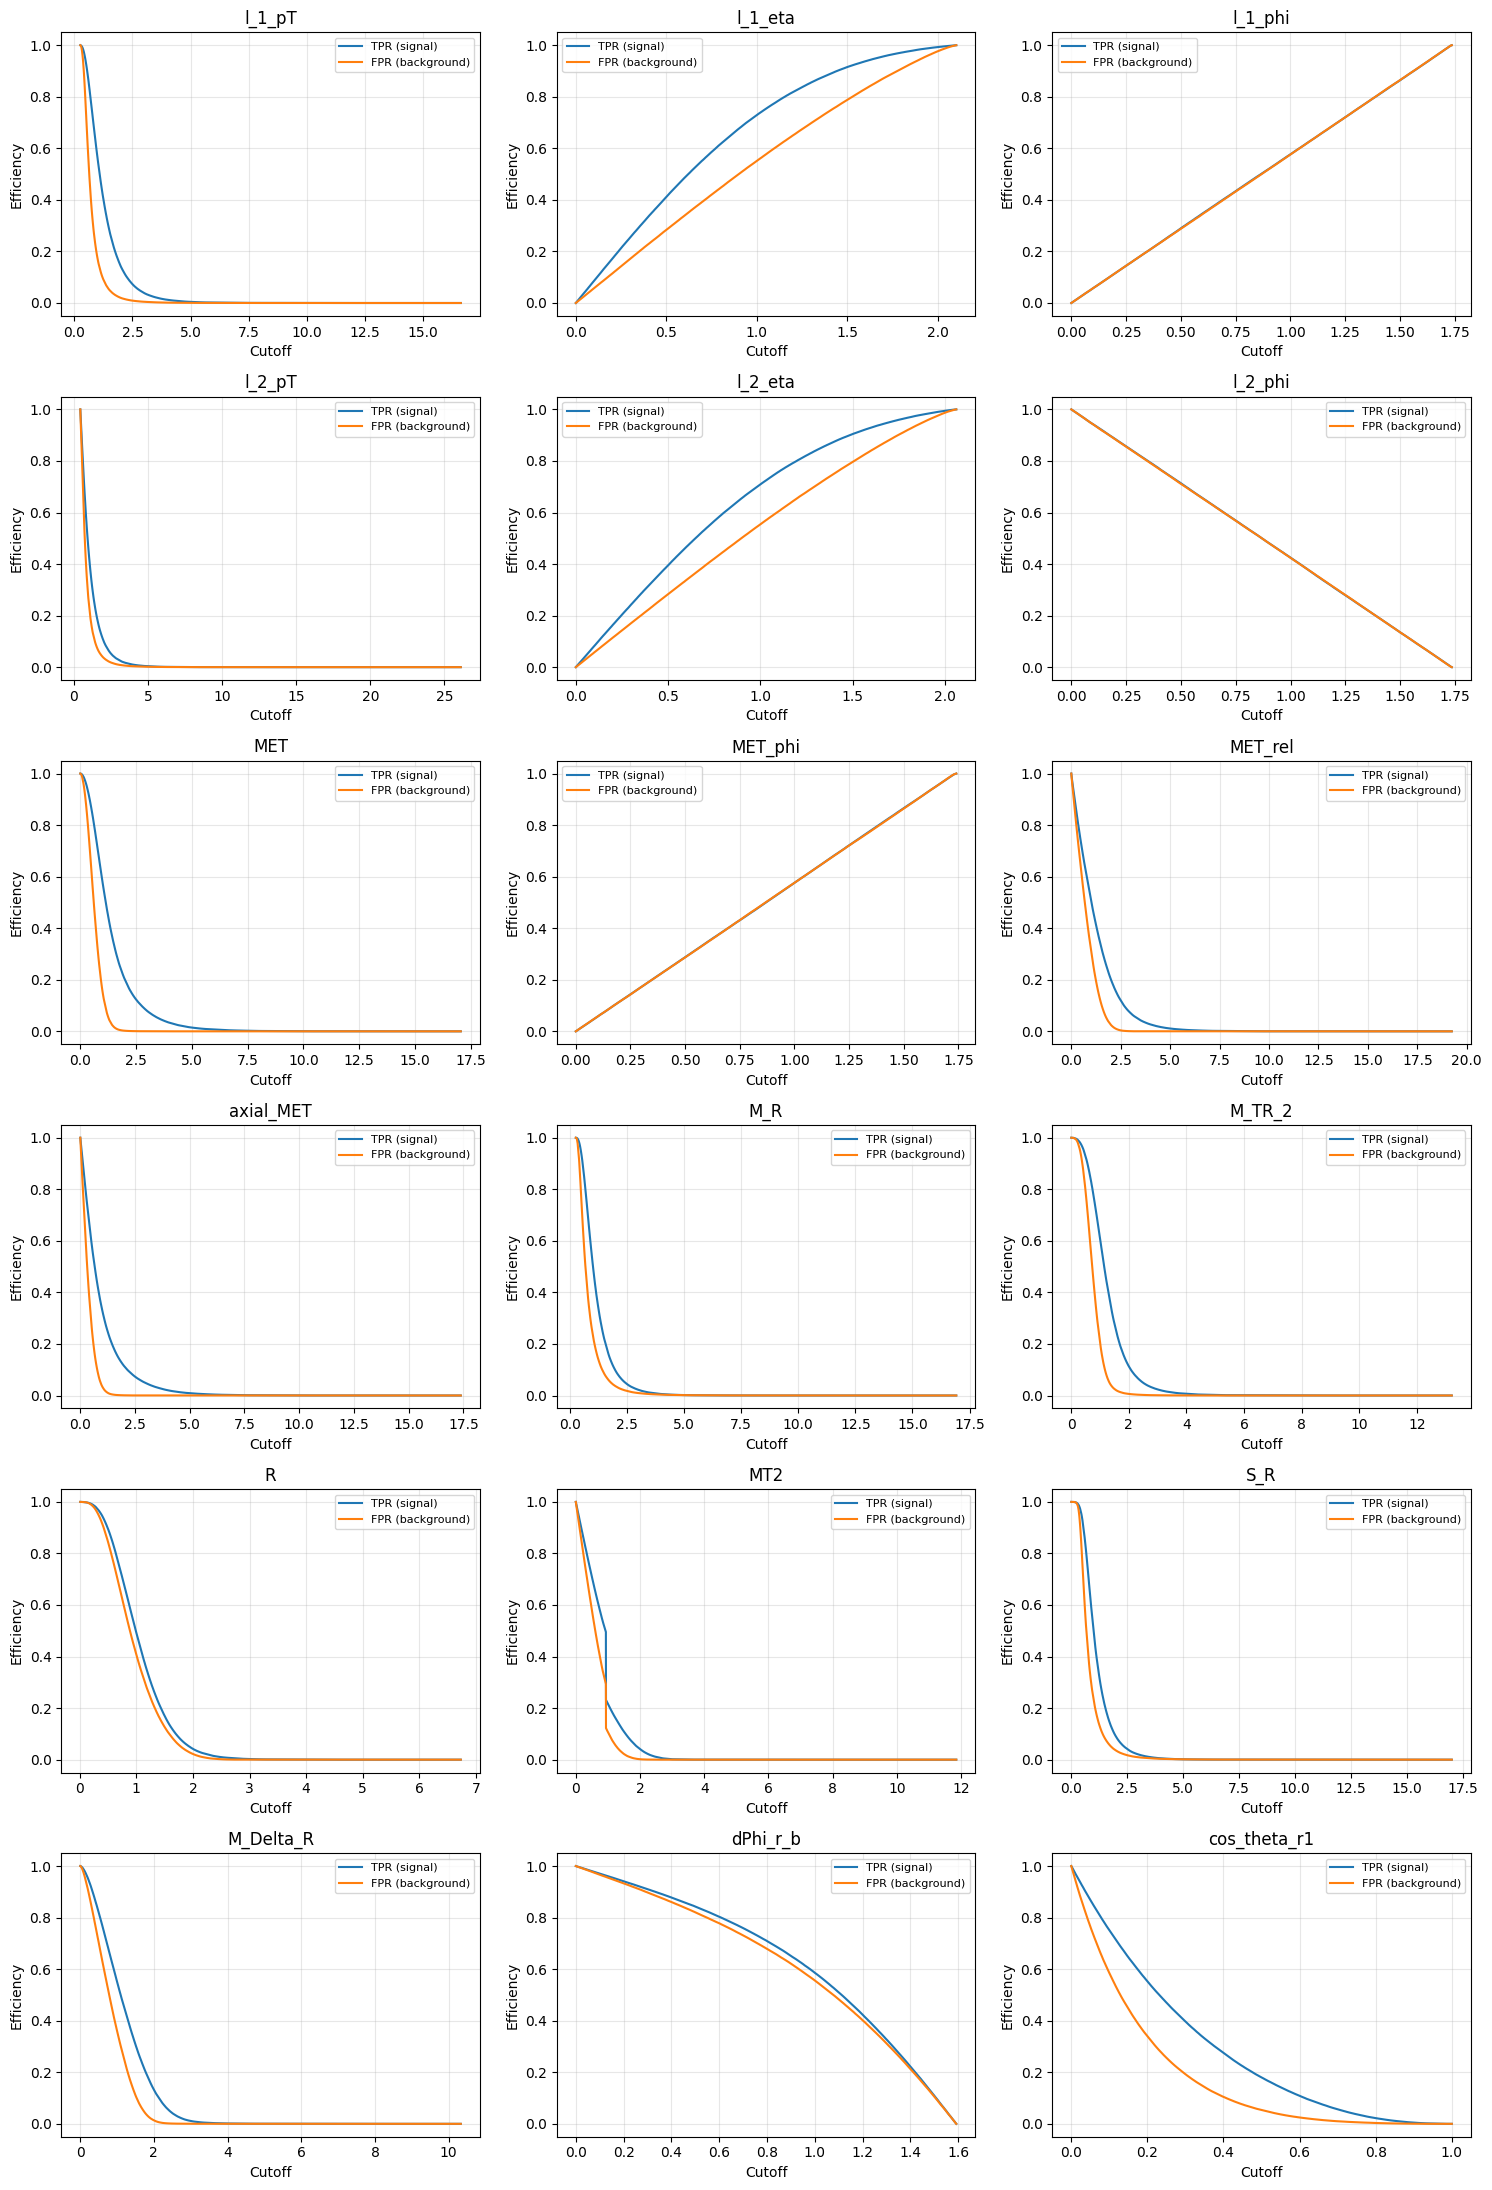

In [26]:
from sklearn.metrics import roc_curve

efficiency_results = {}

fig, axes = plt.subplots(6, 3, figsize=(15, 22))

for ax, name in zip(axes.flatten(), VarNames[1:]):
    x = df[name].to_numpy()
    rule = selection_rules[name]["rule"]
    mu = selection_rules[name]["mu"]

    if rule.startswith("|"):
        x = np.abs(x - mu)

    direction = -1 if "<" in rule else 1
    score = direction * x

    fpr, tpr, thresholds = roc_curve(
        df["signal"], score, drop_intermediate=False
    )

    finite = np.isfinite(thresholds)
    cutoffs = direction * thresholds[finite]
    tpr = tpr[finite]
    fpr = fpr[finite]

    order = np.argsort(cutoffs)
    cutoffs = cutoffs[order]
    tpr = tpr[order]
    fpr = fpr[order]

    efficiency_results[name] = {
        "cutoffs": cutoffs,
        "tpr": tpr,
        "fpr": fpr
    }

    ax.plot(cutoffs, tpr, label="TPR (signal)")
    ax.plot(cutoffs, fpr, label="FPR (background)")
    ax.set_title(name)
    ax.set_xlabel("Cutoff")
    ax.set_ylabel("Efficiency")
    ax.legend(fontsize=8)
    ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()

/tmp/ipykernel_681/15247471.py:48: UserWarning: Creating legend with loc="best" can be slow with large amounts of data.
  plt.tight_layout()
/usr/local/lib/python3.13/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Creating legend with loc="best" can be slow with large amounts of data.
  fig.canvas.print_figure(bytes_io, **kw)


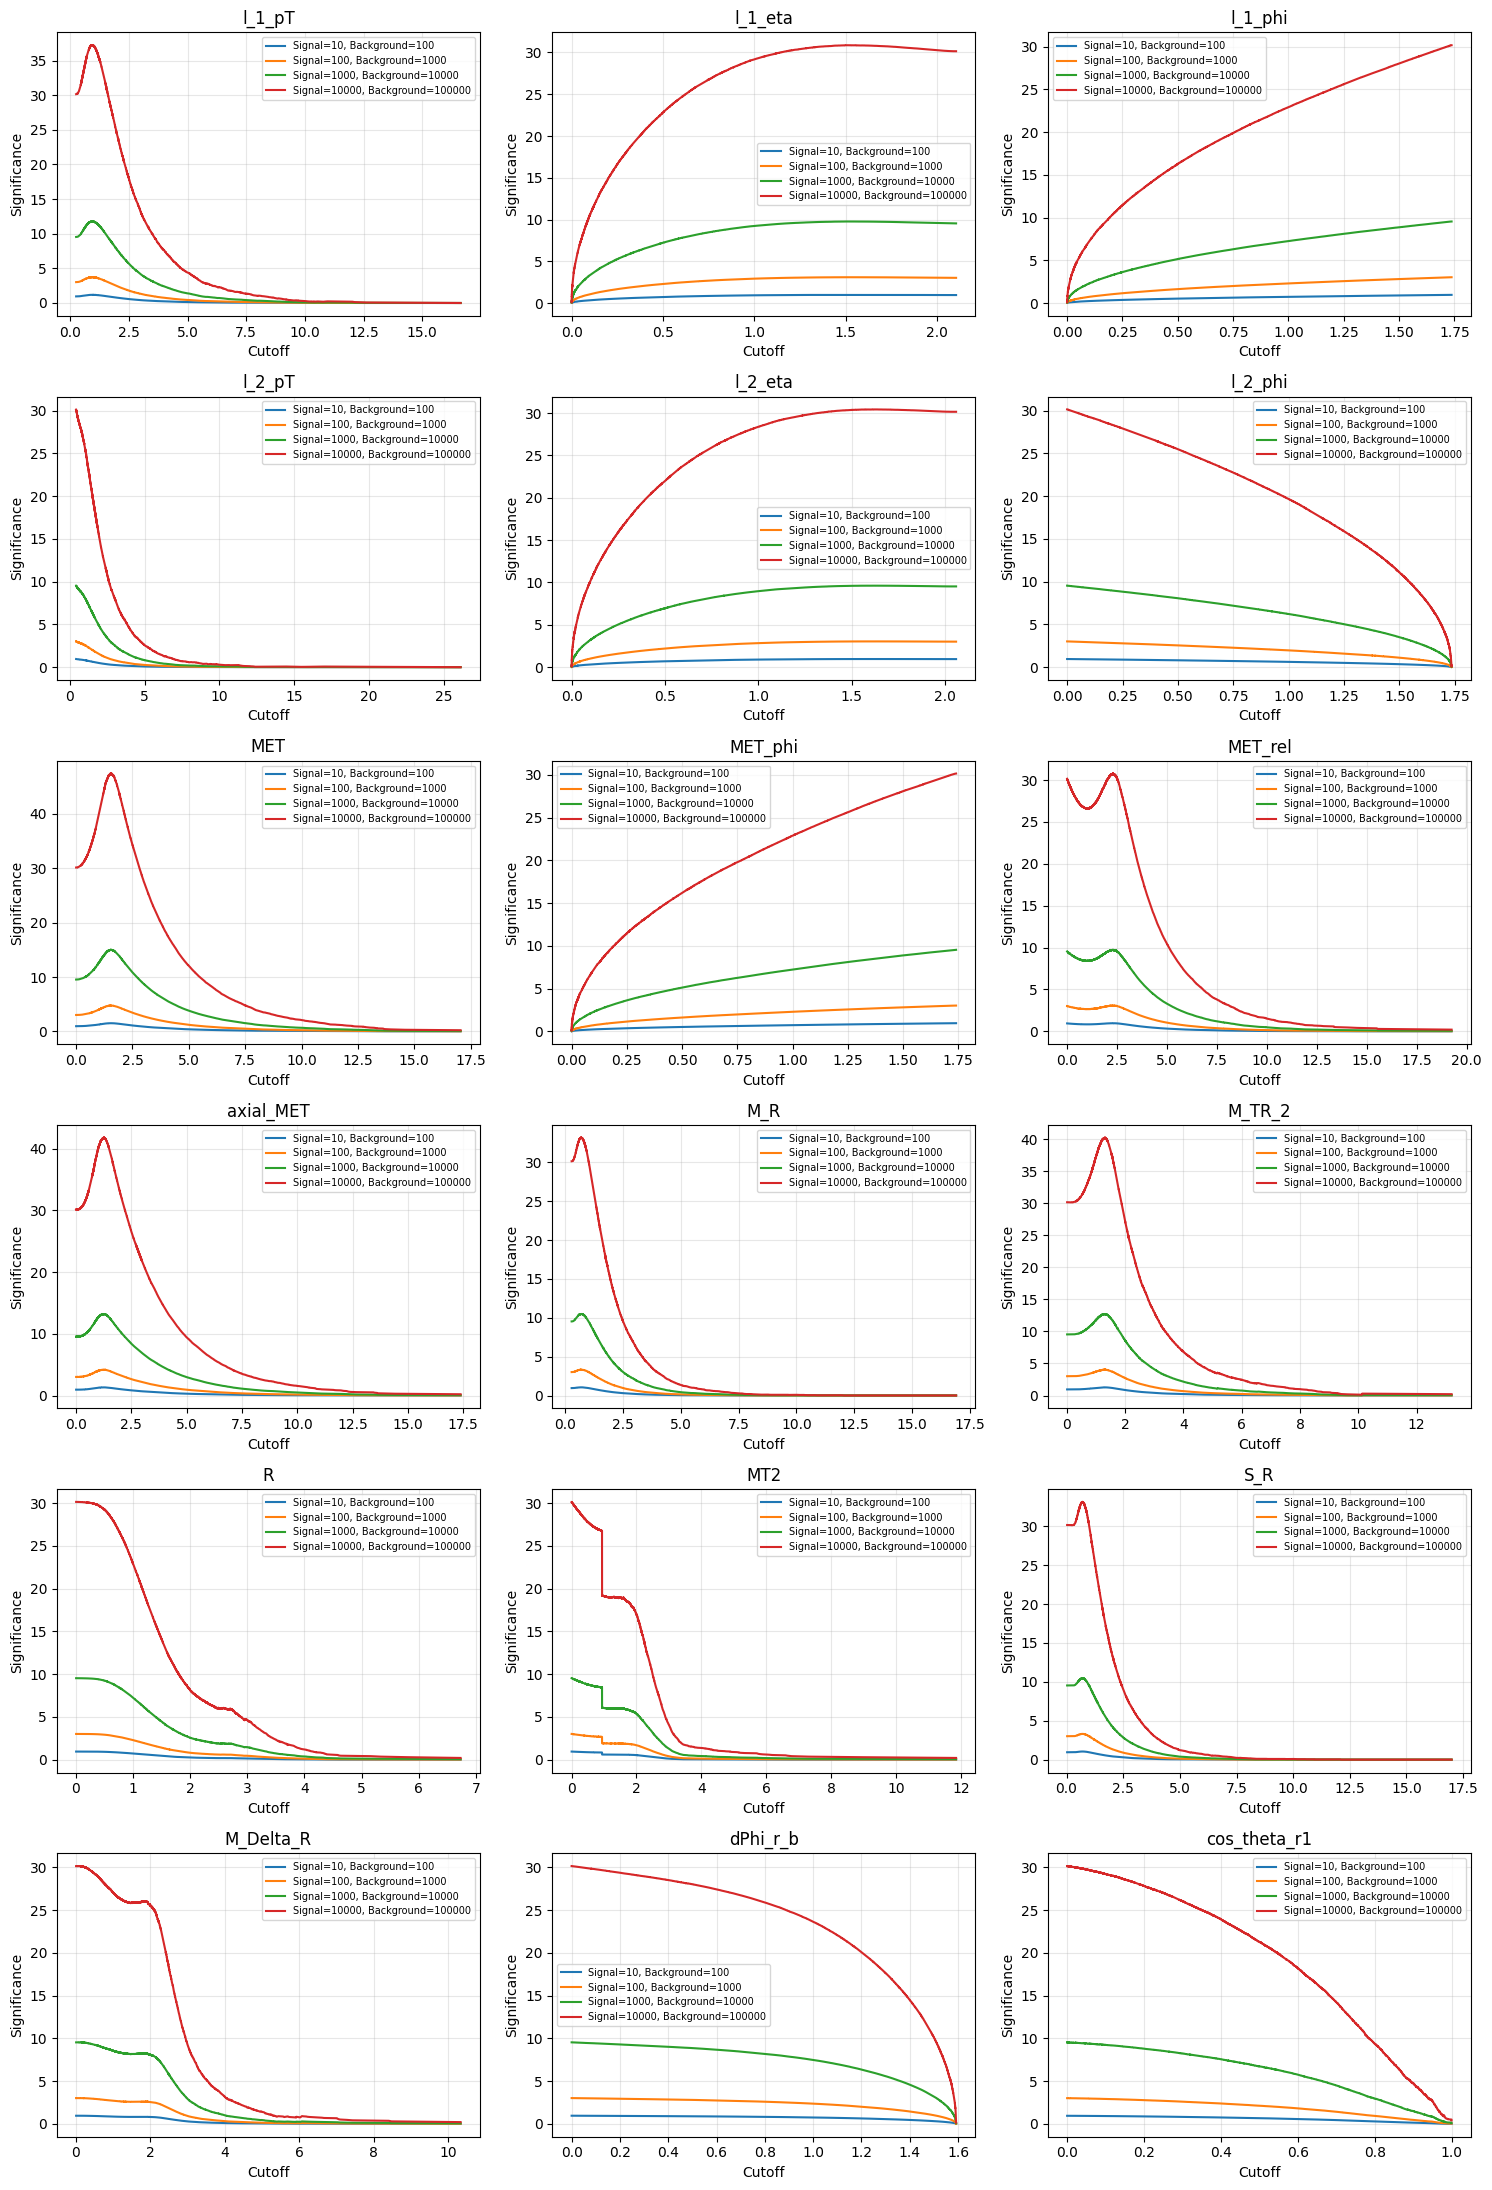

Variable        Signal    Background    Best cutoff    Max significance
------------  --------  ------------  -------------  ------------------
l_1_pT              10           100          0.962               1.177
l_1_pT             100          1000          0.962               3.722
l_1_pT            1000         10000          0.962              11.769
l_1_pT           10000        100000          0.962              37.218
l_1_eta             10           100          1.513               0.976
l_1_eta            100          1000          1.513               3.087
l_1_eta           1000         10000          1.513               9.762
l_1_eta          10000        100000          1.513              30.872
l_1_phi             10           100          1.737               0.953
l_1_phi            100          1000          1.737               3.015
l_1_phi           1000         10000          1.737               9.535
l_1_phi          10000        100000          1.737             

In [27]:
scenarios = [
    (10, 100),
    (100, 1000),
    (1000, 10000),
    (10000, 100000)
]

best_cuts = {}
summary = []

fig, axes = plt.subplots(6, 3, figsize=(15, 22))

for ax, name in zip(axes.flatten(), VarNames[1:]):
    result = efficiency_results[name]
    cutoffs = result["cutoffs"]
    tpr = result["tpr"]
    fpr = result["fpr"]

    for ns, nb in scenarios:
        signal = tpr * ns
        background = fpr * nb

        significance = np.divide(
            signal,
            np.sqrt(signal + background),
            out=np.zeros_like(signal),
            where=(signal + background) > 0
        )

        best = np.argmax(significance)

        best_cuts[(name, ns, nb)] = cutoffs[best]
        summary.append([
            name, ns, nb, cutoffs[best], significance[best]
        ])

        ax.plot(
            cutoffs, significance,
            label=f"Signal={ns}, Background={nb}"
        )

    ax.set_title(name)
    ax.set_xlabel("Cutoff")
    ax.set_ylabel("Significance")
    ax.legend(fontsize=7)
    ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()

print(tabulate(
    summary,
    headers=["Variable", "Signal", "Background",
             "Best cutoff", "Max significance"],
    floatfmt=".3f"
))

## Exercise 6: Cut Flow


### Exercise 6.1

For each above scenario, choose a subset (minimum 3) of observables to use for selections, and values of $x_c$ based on your significance plots (Exercise 5.3).

### Exercise 6.2
Create a "cut-flow" table for each scenario where you successively make the selections on each observable and tabulate $\epsilon_S$, $\epsilon_B$, $N'_S$, $N'_B$, and $\sigma_{S'}$.

### Exercise 6.3
In Exercise 5.3 you computed the significance for each observable assuming to make no other selections on any other observable. If the variables are correlated, then this assumption can lead to non-optimal results when selecting on multiple variables. By looking at the correlation matrices and your answers to Exercise 4.2, identify where this effect could be most detrimental to the significance. Attempt to correct the issue by applying the selection in one observable and then optimizing (as in Exercise 5.3) for a second observable. What happens if you change the order of your selection (make selection on second and optimize on first)?




In [28]:
chosen_variables = ["MET", "axial_MET", "M_TR_2"]

def selection_mask(data, name, cutoff):
    rule = selection_rules[name]["rule"]
    values = data[name].to_numpy()

    if rule.startswith("|"):
        mu = selection_rules[name]["mu"]
        values = np.abs(values - mu)

    if "<" in rule:
        return values <= cutoff
    return values >= cutoff


is_signal = df["signal"].to_numpy() == 1
is_background = ~is_signal

for ns, nb in scenarios:
    keep = np.ones(len(df), dtype=bool)
    rows = []

    for name in [None] + chosen_variables:
        if name is None:
            label = "No cuts"
        else:
            cutoff = best_cuts[(name, ns, nb)]
            keep &= selection_mask(df, name, cutoff)
            label = f"{name}: cutoff {cutoff:.3f}"

        signal_eff = (keep & is_signal).sum() / is_signal.sum()
        background_eff = (
            (keep & is_background).sum() / is_background.sum()
        )

        signal = signal_eff * ns
        background = background_eff * nb
        total = signal + background
        significance = signal / np.sqrt(total) if total > 0 else 0

        rows.append([
            label, signal_eff, background_eff,
            signal, background, significance
        ])

    print(f"\nExpected signal = {ns}, background = {nb}")

    display(HTML(tabulate(
        rows,
        headers=["Selection", "Signal efficiency",
                 "Background efficiency", "Remaining signal",
                 "Remaining background", "Significance"],
        tablefmt="html",
        floatfmt=".4f"
    )))


Expected signal = 10, background = 100


Selection,Signal efficiency,Background efficiency,Remaining signal,Remaining background,Significance
No cuts,1.0000,1.0000,10.0000,100.0000,0.9535
MET: cutoff 1.529,0.3292,0.0152,3.2919,1.5235,1.5001
axial_MET: cutoff 1.273,0.2094,0.0054,2.0936,0.5418,1.2896
M_TR_2: cutoff 1.304,0.1444,0.0047,1.4438,0.4731,1.0428



Expected signal = 100, background = 1000


Selection,Signal efficiency,Background efficiency,Remaining signal,Remaining background,Significance
No cuts,1.0000,1.0000,100.0000,1000.0000,3.0151
MET: cutoff 1.529,0.3292,0.0152,32.9189,15.2352,4.7438
axial_MET: cutoff 1.273,0.2094,0.0054,20.9357,5.4182,4.0782
M_TR_2: cutoff 1.304,0.1444,0.0047,14.4383,4.7312,3.2977



Expected signal = 1000, background = 10000


Selection,Signal efficiency,Background efficiency,Remaining signal,Remaining background,Significance
No cuts,1.0000,1.0000,1000.0000,10000.0000,9.5346
MET: cutoff 1.529,0.3292,0.0152,329.1893,152.3518,15.0013
axial_MET: cutoff 1.273,0.2094,0.0054,209.3568,54.1818,12.8963
M_TR_2: cutoff 1.304,0.1444,0.0047,144.3826,47.3121,10.4282



Expected signal = 10000, background = 100000


Selection,Signal efficiency,Background efficiency,Remaining signal,Remaining background,Significance
No cuts,1.0000,1.0000,10000.0000,100000.0000,30.1511
MET: cutoff 1.529,0.3292,0.0152,3291.8930,1523.5176,47.4383
axial_MET: cutoff 1.273,0.2094,0.0054,2093.5680,541.8182,40.7817
M_TR_2: cutoff 1.304,0.1444,0.0047,1443.8265,473.1215,32.9769


## Exercise 7: ROC Curves

### Exercise 7.1
For the top 3 observables you identified earlier, create one figure overlaying the Receiver Operating Characteristic (ROC) curves for the 3 observables. Compute the area under the curves and report it in the legend of the figure.

### Exercise 7.2
Write a function that you can use to quickly create the figure in Exercise 7.1 with other observables and different conditions. Note that you will likely revise this function as you do the remainder of the lab.

### Exercise 7.3
Use the function from Exercise 7.2 to compare the ROC curves for the successive selections in Exercise 6. Specifically, plot the ROC curve after each selection.

### Exercise 7.4
Use your function and appropriate example to demonstrate the effect (if any) of changing order of the successive selections.



In [29]:
# Check correlations between the selected variables
display(df[chosen_variables].corr())

def optimize_second(first, second, ns=10, nb=100):
    first_cutoff = best_cuts[(first, ns, nb)]
    keep_first = selection_mask(df, first, first_cutoff)

    # Include an option that applies no second cut
    best_significance = -1
    best_cutoff = None

    candidates = [None] + list(
        efficiency_results[second]["cutoffs"]
    )

    # Use sorted scores to avoid checking every row for every cutoff
    values = df[second].to_numpy()
    rule = selection_rules[second]["rule"]

    if rule.startswith("|"):
        values = np.abs(values - selection_rules[second]["mu"])

    sig_values = np.sort(values[keep_first & is_signal])
    bkg_values = np.sort(values[keep_first & is_background])

    cutoffs = np.array(candidates[1:])

    if "<" in rule:
        sig_counts = np.searchsorted(sig_values, cutoffs, side="right")
        bkg_counts = np.searchsorted(bkg_values, cutoffs, side="right")
    else:
        sig_counts = len(sig_values) - np.searchsorted(
            sig_values, cutoffs, side="left"
        )
        bkg_counts = len(bkg_values) - np.searchsorted(
            bkg_values, cutoffs, side="left"
        )

    sig_counts = np.r_[len(sig_values), sig_counts]
    bkg_counts = np.r_[len(bkg_values), bkg_counts]

    signal = ns * sig_counts / is_signal.sum()
    background = nb * bkg_counts / is_background.sum()

    significance = np.divide(
        signal,
        np.sqrt(signal + background),
        out=np.zeros_like(signal),
        where=(signal + background) > 0
    )

    best = np.argmax(significance)
    best_cutoff = candidates[best]

    return [
        first, first_cutoff, second,
        "No second cut" if best_cutoff is None else f"{best_cutoff:.4f}",
        significance[best]
    ]

order_results = []

for second in ["axial_MET", "M_TR_2"]:
    order_results.append(optimize_second("MET", second))
    order_results.append(optimize_second(second, "MET"))

print(tabulate(
    order_results,
    headers=["First variable", "First cutoff", "Second variable",
             "Optimized second cutoff", "Significance"],
    floatfmt=".4f"
))

,MET,axial_MET,M_TR_2
MET,1.000000,0.175867,0.719661
axial_MET,0.175867,1.000000,-0.317468
M_TR_2,0.719661,-0.317468,1.000000


First variable      First cutoff  Second variable    Optimized second cutoff      Significance
----------------  --------------  -----------------  -------------------------  --------------
MET                       1.5291  axial_MET          No second cut                      1.5001
axial_MET                 1.2727  MET                1.1782                             1.3359
MET                       1.5291  M_TR_2             No second cut                      1.5001
M_TR_2                    1.3043  MET                1.4286                             1.2821


MET and M_TR_2 have a strong positive correlation of about 0.720, so they provide overlapping information. After applying the best MET cut, neither additional cut improved significance. Keeping only MET gave 1.5001. Starting with axial_MET and optimizing MET gave 1.3359, while starting with M_TR_2 and optimizing MET gave 1.2821. The order matters here because the first cutoff stays fixed while the second is optimized. Applying the same fixed cuts in a different order would give identical results.

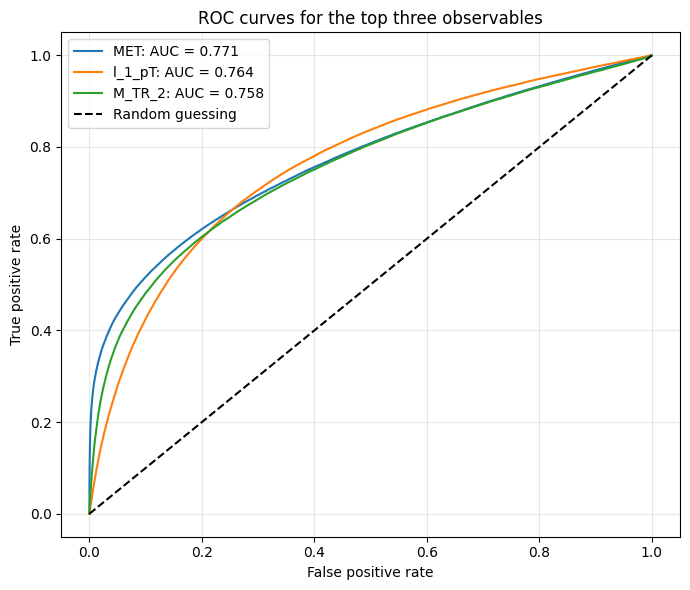

In [30]:
from sklearn.metrics import auc

def plot_rocs(data, names, title="ROC curves"):
    plt.figure(figsize=(7, 6))

    for name in names:
        values = data[name].to_numpy()
        rule = selection_rules[name]["rule"]

        if rule.startswith("|"):
            values = np.abs(
                values - selection_rules[name]["mu"]
            )

        if "<" in rule:
            values = -values

        fpr, tpr, _ = roc_curve(data["signal"], values)
        area = auc(fpr, tpr)

        plt.plot(fpr, tpr, label=f"{name}: AUC = {area:.3f}")

    plt.plot([0, 1], [0, 1], "k--", label="Random guessing")
    plt.xlabel("False positive rate")
    plt.ylabel("True positive rate")
    plt.title(title)
    plt.legend()
    plt.grid(alpha=0.3)
    plt.tight_layout()
    plt.show()

plot_rocs(
    df,
    ["MET", "l_1_pT", "M_TR_2"],
    "ROC curves for the top three observables"
)

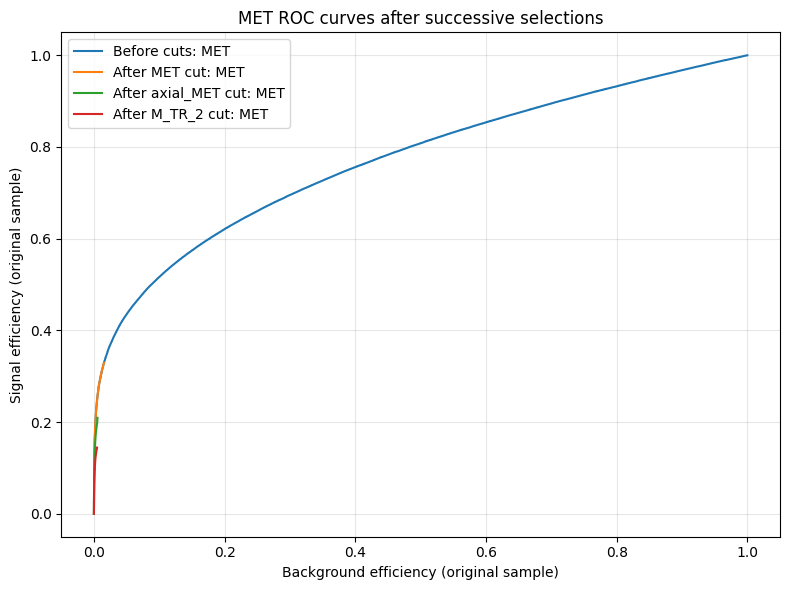

In [31]:
def plot_rocs(data, names, title="ROC curves", keep=None):
    if keep is None:
        keep = np.ones(len(data), dtype=bool)

    selected = data.loc[keep]
    labels = data["signal"].to_numpy()

    signal_fraction = (
        selected["signal"].eq(1).sum() / (labels == 1).sum()
    )
    background_fraction = (
        selected["signal"].eq(0).sum() / (labels == 0).sum()
    )

    for name in names:
        values = selected[name].to_numpy()
        rule = selection_rules[name]["rule"]

        if rule.startswith("|"):
            values = np.abs(
                values - selection_rules[name]["mu"]
            )

        if "<" in rule:
            values = -values

        fpr, tpr, _ = roc_curve(selected["signal"], values)

        plt.plot(
            fpr * background_fraction,
            tpr * signal_fraction,
            label=f"{title}: {name}"
        )


plt.figure(figsize=(8, 6))
keep = np.ones(len(df), dtype=bool)

plot_rocs(df, ["MET"], "Before cuts", keep)

for name in chosen_variables:
    cutoff = best_cuts[(name, 10, 100)]
    keep &= selection_mask(df, name, cutoff)
    plot_rocs(df, ["MET"], f"After {name} cut", keep)

plt.xlabel("Background efficiency (original sample)")
plt.ylabel("Signal efficiency (original sample)")
plt.title("MET ROC curves after successive selections")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

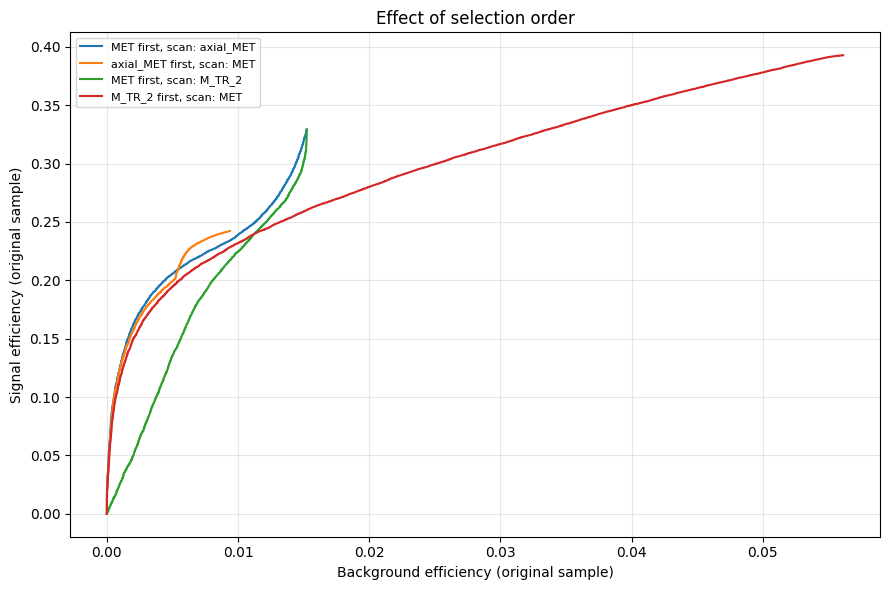

In [32]:
orders = [
    ("MET", "axial_MET"),
    ("axial_MET", "MET"),
    ("MET", "M_TR_2"),
    ("M_TR_2", "MET")
]

plt.figure(figsize=(9, 6))

for first, second in orders:
    first_cutoff = best_cuts[(first, 10, 100)]
    keep = selection_mask(df, first, first_cutoff)

    plot_rocs(
        df,
        [second],
        title=f"{first} first, scan",
        keep=keep
    )

plt.xlabel("Background efficiency (original sample)")
plt.ylabel("Signal efficiency (original sample)")
plt.title("Effect of selection order")
plt.legend(fontsize=8)
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

Changing the order changes the available ROC curve because a different first cut removes events before the second variable is scanned. MET first gave the highest maximum significance, 1.5001, with no additional cut needed. Reversing the order gave lower maximum significance. If both cutoff values stay fixed, changing their order gives the same final selection.

## Exercise 8: Linear Discriminant

This is Fisher's linear discriminant, which the machine-learning lectures cover.

### Exercise 8.1

Using numpy, compute the between-class $\bf{S}_B$ and within-class $\bf{S}_W$ covariance matrices defined as:

$$
\bf{S}_B = (\bf{m_2}-\bf{m_1})(\bf{m_2}-\bf{m_1})^T \\
$$
$$
\bf{S}_W = \sum_{i=1,2} \sum_{n=1}^{l_i} (\bf{x}_n^i - \bf{m}_i) (\bf{x}_n^i - \bf{m}_i)^T
$$

where $\bf{m_i}$ are the vectors containing the means for category 1 and 2, here defined as signal and background. Here $\bf{x}_n^i$ is the vector containing the observables for the $n$th example event in category $i$.

### Exercise 8.2

Compute the linear coefficients $\bf{w} = \bf{S_W}^{-1}(\bf{m_2}-\bf{m_1})$. Compare the histogram of the distribution of $F_n^i=\bf{w}^T\bf{x}_n^i$ for the two categories.

### Exercise 8.3

Draw the ROC curve for $F_n$.

### Exercise 8.4

What is the maximal significance you can obtain in the scenarios in exercise 5?

Between-class matrix:


,l_1_pT,l_1_eta,l_1_phi,l_2_pT,l_2_eta,l_2_phi,MET,MET_phi,MET_rel,axial_MET,M_R,M_TR_2,R,MT2,S_R,M_Delta_R,dPhi_r_b,cos_theta_r1
l_1_pT,0.287970,4.589223e-04,4.674674e-04,0.138149,0.001541,3.660956e-04,0.413461,-6.366181e-04,0.271136,0.085466,0.182332,0.266558,0.055323,0.073782,0.174242,0.184116,0.015406,0.056628
l_1_eta,0.000459,7.313592e-07,7.449771e-07,0.000220,0.000002,5.834263e-07,0.000659,-1.014543e-06,0.000432,0.000136,0.000291,0.000425,0.000088,0.000118,0.000278,0.000293,0.000025,0.000090
l_1_phi,0.000467,7.449771e-07,7.588486e-07,0.000224,0.000003,5.942897e-07,0.000671,-1.033434e-06,0.000440,0.000139,0.000296,0.000433,0.000090,0.000120,0.000283,0.000299,0.000025,0.000092
l_2_pT,0.138149,2.201599e-04,2.242593e-04,0.066274,0.000739,1.756279e-04,0.198351,-3.054063e-04,0.130073,0.041001,0.087470,0.127876,0.026540,0.035396,0.083589,0.088327,0.007391,0.027166
l_2_eta,0.001541,2.455298e-06,2.501015e-06,0.000739,0.000008,1.958662e-06,0.002212,-3.405995e-06,0.001451,0.000457,0.000975,0.001426,0.000296,0.000395,0.000932,0.000985,0.000082,0.000303
l_2_phi,0.000366,5.834263e-07,5.942897e-07,0.000176,0.000002,4.654160e-07,0.000526,-8.093304e-07,0.000345,0.000109,0.000232,0.000339,0.000070,0.000094,0.000222,0.000234,0.000020,0.000072
MET,0.413461,6.589106e-04,6.711795e-04,0.198351,0.002212,5.256320e-04,0.593639,-9.140423e-04,0.389291,0.122710,0.261788,0.382718,0.079431,0.105935,0.250173,0.264350,0.022119,0.081305
MET_phi,-0.000637,-1.014543e-06,-1.033434e-06,-0.000305,-0.000003,-8.093304e-07,-0.000914,1.407377e-06,-0.000599,-0.000189,-0.000403,-0.000589,-0.000122,-0.000163,-0.000385,-0.000407,-0.000034,-0.000125
MET_rel,0.271136,4.320949e-04,4.401405e-04,0.130073,0.001451,3.446946e-04,0.389291,-5.994030e-04,0.255286,0.080470,0.171673,0.250975,0.052089,0.069469,0.164056,0.173354,0.014505,0.053318
axial_MET,0.085466,1.362020e-04,1.387381e-04,0.041001,0.000457,1.086523e-04,0.122710,-1.889397e-04,0.080470,0.025365,0.054114,0.079111,0.016419,0.021898,0.051713,0.054643,0.004572,0.016806


Within-class matrix:


,l_1_pT,l_1_eta,l_1_phi,l_2_pT,l_2_eta,l_2_phi,MET,MET_phi,MET_rel,axial_MET,M_R,M_TR_2,R,MT2,S_R,M_Delta_R,dPhi_r_b,cos_theta_r1
l_1_pT,197992.314222,-255.306615,-19.720051,135369.126926,-365.670849,323.221047,62890.484946,-389.327463,15103.484874,-15475.839600,159581.488411,110521.397574,-36718.849769,-15358.632160,149663.061620,26013.428669,-25386.959587,4051.875587
l_1_eta,-255.306615,502149.623006,-428.906989,-108.782977,204155.733837,-521.076631,-1155.282987,-294.357629,-738.924286,-571.353000,-312.983919,-387.193278,139.704991,198.964347,-336.474893,-530.158934,-373.212146,149.612912
l_1_phi,-19.720051,-428.906989,501985.583989,628.639491,125.046741,-133404.896001,299.862992,-92401.675464,298.463939,-953.566382,494.789240,380.674792,89.649144,515.276528,696.768816,413.513165,494.047379,118.137455
l_2_pT,135369.126926,-108.782977,628.639491,204517.454736,-379.537641,56.139663,15102.895278,-742.970965,-16413.989358,20575.119612,151858.466763,65595.995445,-52970.097073,-38836.833053,150592.986841,-8106.923835,-2834.781223,-17327.478373
l_2_eta,-365.670849,204155.733837,125.046741,-379.537641,503130.198981,220.550544,-83.777970,-160.801601,362.067173,-434.987657,-424.931720,-167.598626,123.568959,650.442433,-455.014623,212.934766,-163.667245,110.560041
l_2_phi,323.221047,-521.076631,-133404.896001,56.139663,220.550544,501898.100374,-217.238662,-17717.015666,680.725023,-913.738111,351.181900,212.392348,266.841154,1117.928545,425.719861,634.239598,-123.035647,9.583066
MET,62890.484946,-1155.282987,299.862992,15102.895278,-83.777970,-217.238662,307430.190195,-1282.593998,224914.071362,61744.917531,39762.776556,135086.679216,84095.427281,64241.773945,51715.188224,124755.337402,70094.967950,26452.977638
MET_phi,-389.327463,-294.357629,-92401.675464,-742.970965,-160.801601,-17717.015666,-1282.593998,501655.398054,-2373.187735,-197.440345,-691.535845,-527.346940,-99.582582,62.182577,-805.554513,-234.397288,-850.300479,75.242987
MET_rel,15103.484874,-738.924286,298.463939,-16413.989358,362.067173,680.725023,224914.071362,-2373.187735,363552.912060,-69914.850974,531.001209,119840.321435,117945.325156,195765.226740,20791.938560,185851.266182,71418.908994,21040.095977
axial_MET,-15475.839600,-571.353000,-953.566382,20575.119612,-434.987657,-913.738111,61744.917531,-197.440345,-69914.850974,499537.193740,1849.679839,-102328.897303,-92488.124909,-233217.180850,-27110.895967,-123320.090749,-13123.956285,-28953.700291


Linear coefficients:


,Coefficient
l_1_pT,2.268330e-06
l_1_eta,5.636884e-09
l_1_phi,2.104239e-09
l_2_pT,9.955830e-07
l_2_eta,3.484522e-09
l_2_phi,2.707626e-09
MET,1.651854e-06
MET_phi,2.742418e-09
MET_rel,1.397233e-07
axial_MET,2.642057e-07


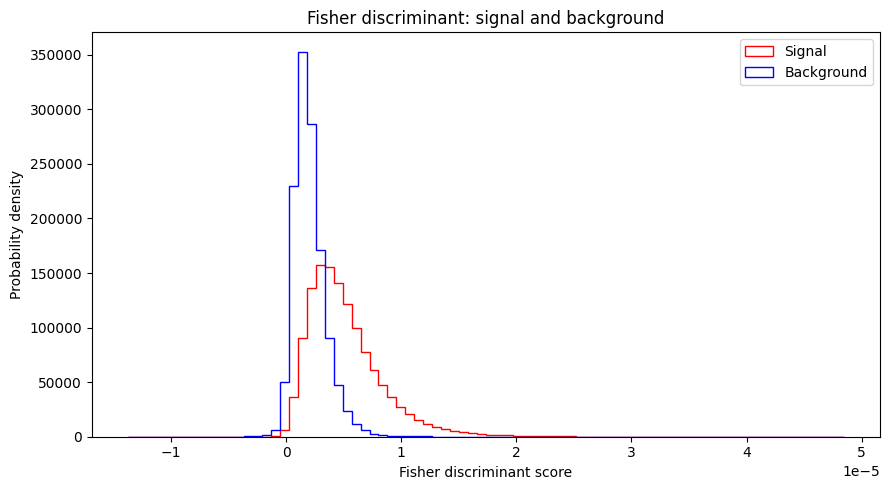

In [33]:
names = VarNames[1:]

background_data = df_bkg[names].to_numpy()
signal_data = df_sig[names].to_numpy()

m1 = background_data.mean(axis=0)
m2 = signal_data.mean(axis=0)

difference = m2 - m1

S_B = np.outer(difference, difference)

background_centered = background_data - m1
signal_centered = signal_data - m2

S_W = (
    background_centered.T @ background_centered
    + signal_centered.T @ signal_centered
)

w = np.linalg.pinv(S_W) @ difference

print("Between-class matrix:")
display(pd.DataFrame(S_B, index=names, columns=names))

print("Within-class matrix:")
display(pd.DataFrame(S_W, index=names, columns=names))

print("Linear coefficients:")
display(pd.Series(w, index=names, name="Coefficient"))

fisher_scores = df[names].to_numpy() @ w

bins = np.histogram_bin_edges(fisher_scores, bins=80)

plt.figure(figsize=(9, 5))
plt.hist(
    fisher_scores[is_signal],
    bins=bins, density=True, histtype="step",
    color="red", label="Signal"
)
plt.hist(
    fisher_scores[is_background],
    bins=bins, density=True, histtype="step",
    color="blue", label="Background"
)
plt.xlabel("Fisher discriminant score")
plt.ylabel("Probability density")
plt.title("Fisher discriminant: signal and background")
plt.legend()
plt.tight_layout()
plt.show()

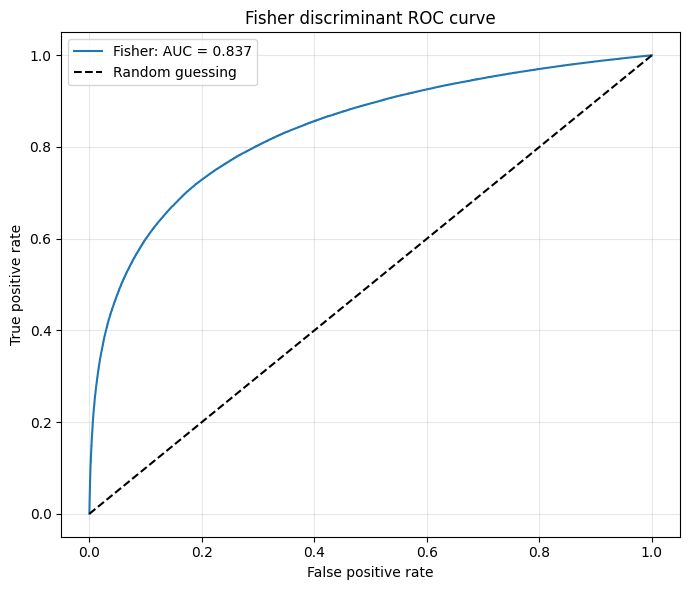

  Expected signal    Expected background    Best Fisher cutoff    Signal efficiency    Background efficiency    Max significance
-----------------  ---------------------  --------------------  -------------------  -----------------------  ------------------
               10                    100          4.497611e-06               0.4916                   0.0537              1.5326
              100                   1000          4.497611e-06               0.4916                   0.0537              4.8464
             1000                  10000          4.497611e-06               0.4916                   0.0537             15.3257
            10000                 100000          4.497611e-06               0.4916                   0.0537             48.4641

Fisher AUC: 0.8375


In [34]:
fpr, tpr, thresholds = roc_curve(
    df["signal"], fisher_scores,
    drop_intermediate=False
)

fisher_auc = auc(fpr, tpr)

plt.figure(figsize=(7, 6))
plt.plot(fpr, tpr, label=f"Fisher: AUC = {fisher_auc:.3f}")
plt.plot([0, 1], [0, 1], "k--", label="Random guessing")
plt.xlabel("False positive rate")
plt.ylabel("True positive rate")
plt.title("Fisher discriminant ROC curve")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

rows = []

for ns, nb in scenarios:
    signal = tpr * ns
    background = fpr * nb

    significance = np.divide(
        signal,
        np.sqrt(signal + background),
        out=np.zeros_like(signal),
        where=(signal + background) > 0
    )

    best = np.argmax(significance)

    rows.append([
        ns, nb, thresholds[best],
        tpr[best], fpr[best],
        significance[best]
    ])

print(tabulate(
    rows,
    headers=["Expected signal", "Expected background",
             "Best Fisher cutoff", "Signal efficiency",
             "Background efficiency", "Max significance"],
    floatfmt=(".0f", ".0f", ".6e", ".4f", ".4f", ".4f")
))

print(f"\nFisher AUC: {fisher_auc:.4f}")

The best Fisher cutoff was about 4.498 × 10⁻⁶. It kept 49.16% of signal events and 5.37% of background events. The maximum significances were 1.5326, 4.8464, 15.3257, and 48.4641 for the four scenarios. This slightly improved on MET alone, which gave 1.5001 in the smallest scenario. The cutoff stayed the same because all scenarios had the same signal-to-background ratio. These results use the same data used to calculate the Fisher coefficients.